# Problem with trial detection in ball-return experiments

In [50]:
import matplotlib.pyplot as plt
import numpy as np
import plotnine as p9
import polars as pl
import tqdm

data = pl.concat(
    [
        pl.read_ipc(file, columns=["fly", "time", "trial", "trial_time", "y_ball_0"])
        for file in [
            "../Datasets/Multi-trials_trajectories-1.feather",
            "../Datasets/Multi-trials_trajectories-2.feather",
        ]
    ]
)
data

Could not memory_map compressed IPC file, defaulting to normal read. Toggle off 'memory_map' to silence this warning.
Could not memory_map compressed IPC file, defaulting to normal read. Toggle off 'memory_map' to silence this warning.


fly,time,trial,trial_time,y_ball_0
str,f64,f64,f64,f64
"""240726_Learning_Videos_Tracked…",0.034483,1.0,0.0,-157.226849
"""240726_Learning_Videos_Tracked…",0.068966,1.0,0.034483,-157.226938
"""240726_Learning_Videos_Tracked…",0.103448,1.0,0.068966,-157.227026
"""240726_Learning_Videos_Tracked…",0.137931,1.0,0.103448,-157.227115
"""240726_Learning_Videos_Tracked…",0.172414,1.0,0.137931,-157.227203
…,…,…,…,…
"""240723_Learning_Videos_Tracked…",7200.034483,null,null,-114.122119
"""240723_Learning_Videos_Tracked…",7200.068966,null,null,-114.12207
"""240723_Learning_Videos_Tracked…",7200.103448,null,null,-114.122021


## Replicate paper figure

Plot the trial durations for each fly that has at least 4 trials - this matches the paper nicely

64 flies completed 4 trials


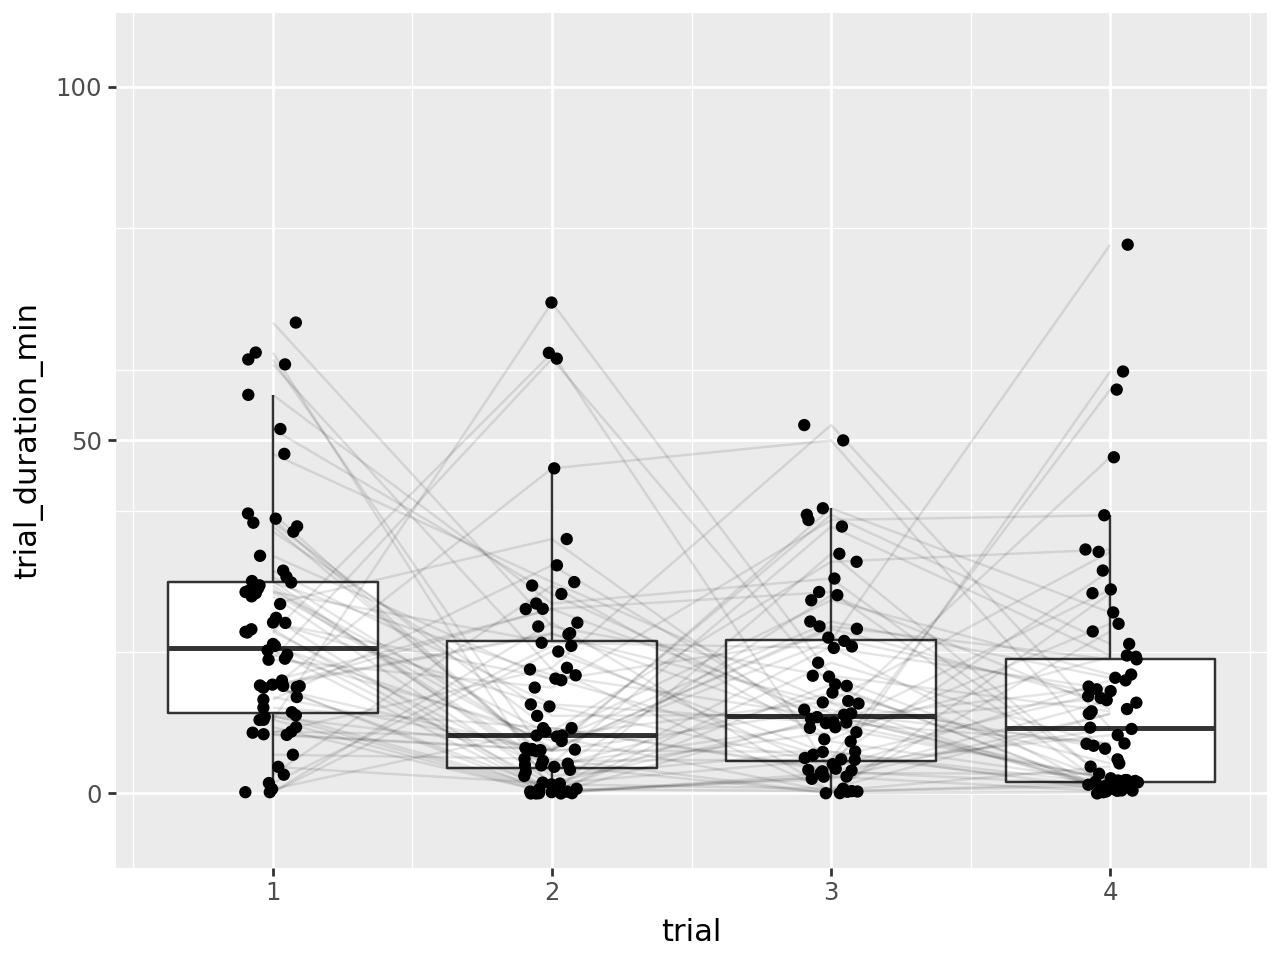

In [57]:
def plot_trial_durations(trial_durations):
    return (
        p9.ggplot(trial_durations, p9.aes(x="trial", y="trial_duration_min", group="trial"))
        + p9.geom_boxplot(outlier_shape="")
        + p9.geom_jitter(width=0.1)
        + p9.geom_line(p9.aes(group="fly"), alpha=0.1)
    )


filtered_data = data.filter(pl.col("trial") <= 4).filter(pl.n_unique("trial").over("fly") >= 4)
print(f"{filtered_data.n_unique('fly')} flies completed 4 trials")
trial_durations_original = filtered_data.group_by("fly", "trial").agg(
    trial_duration_min=1 / 60 * (pl.col("trial_time").max() - pl.col("trial_time").min())
)

(
    plot_trial_durations(trial_durations_original)
    + p9.scale_y_continuous(
        breaks=list(np.arange(0, 101, 50)), limits=(-5, 105), minor_breaks=list(np.linspace(0, 100, 6))
    )
)

But some of these trial durations are 0 or very small, which is weird

In [60]:
trial_durations_original.sort("trial_duration_min")

fly,trial,trial_duration_min
str,f64,f64
"""240723_Learning_Videos_Tracked…",2.0,0.0
"""240723_Learning_Videos_Tracked…",2.0,0.0
"""240723_Learning_Videos_Tracked…",2.0,0.0
"""240723_Learning_Videos_Tracked…",4.0,0.009195
"""240723_Learning_Videos_Tracked…",3.0,0.031034
…,…,…
"""240723_Learning_Videos_Tracked…",2.0,62.367241
"""240717_Learning_Videos_Tracked…",1.0,62.40977
"""240717_Learning_Videos_Tracked…",1.0,66.653448


## Visualising trials boundaries for one fly

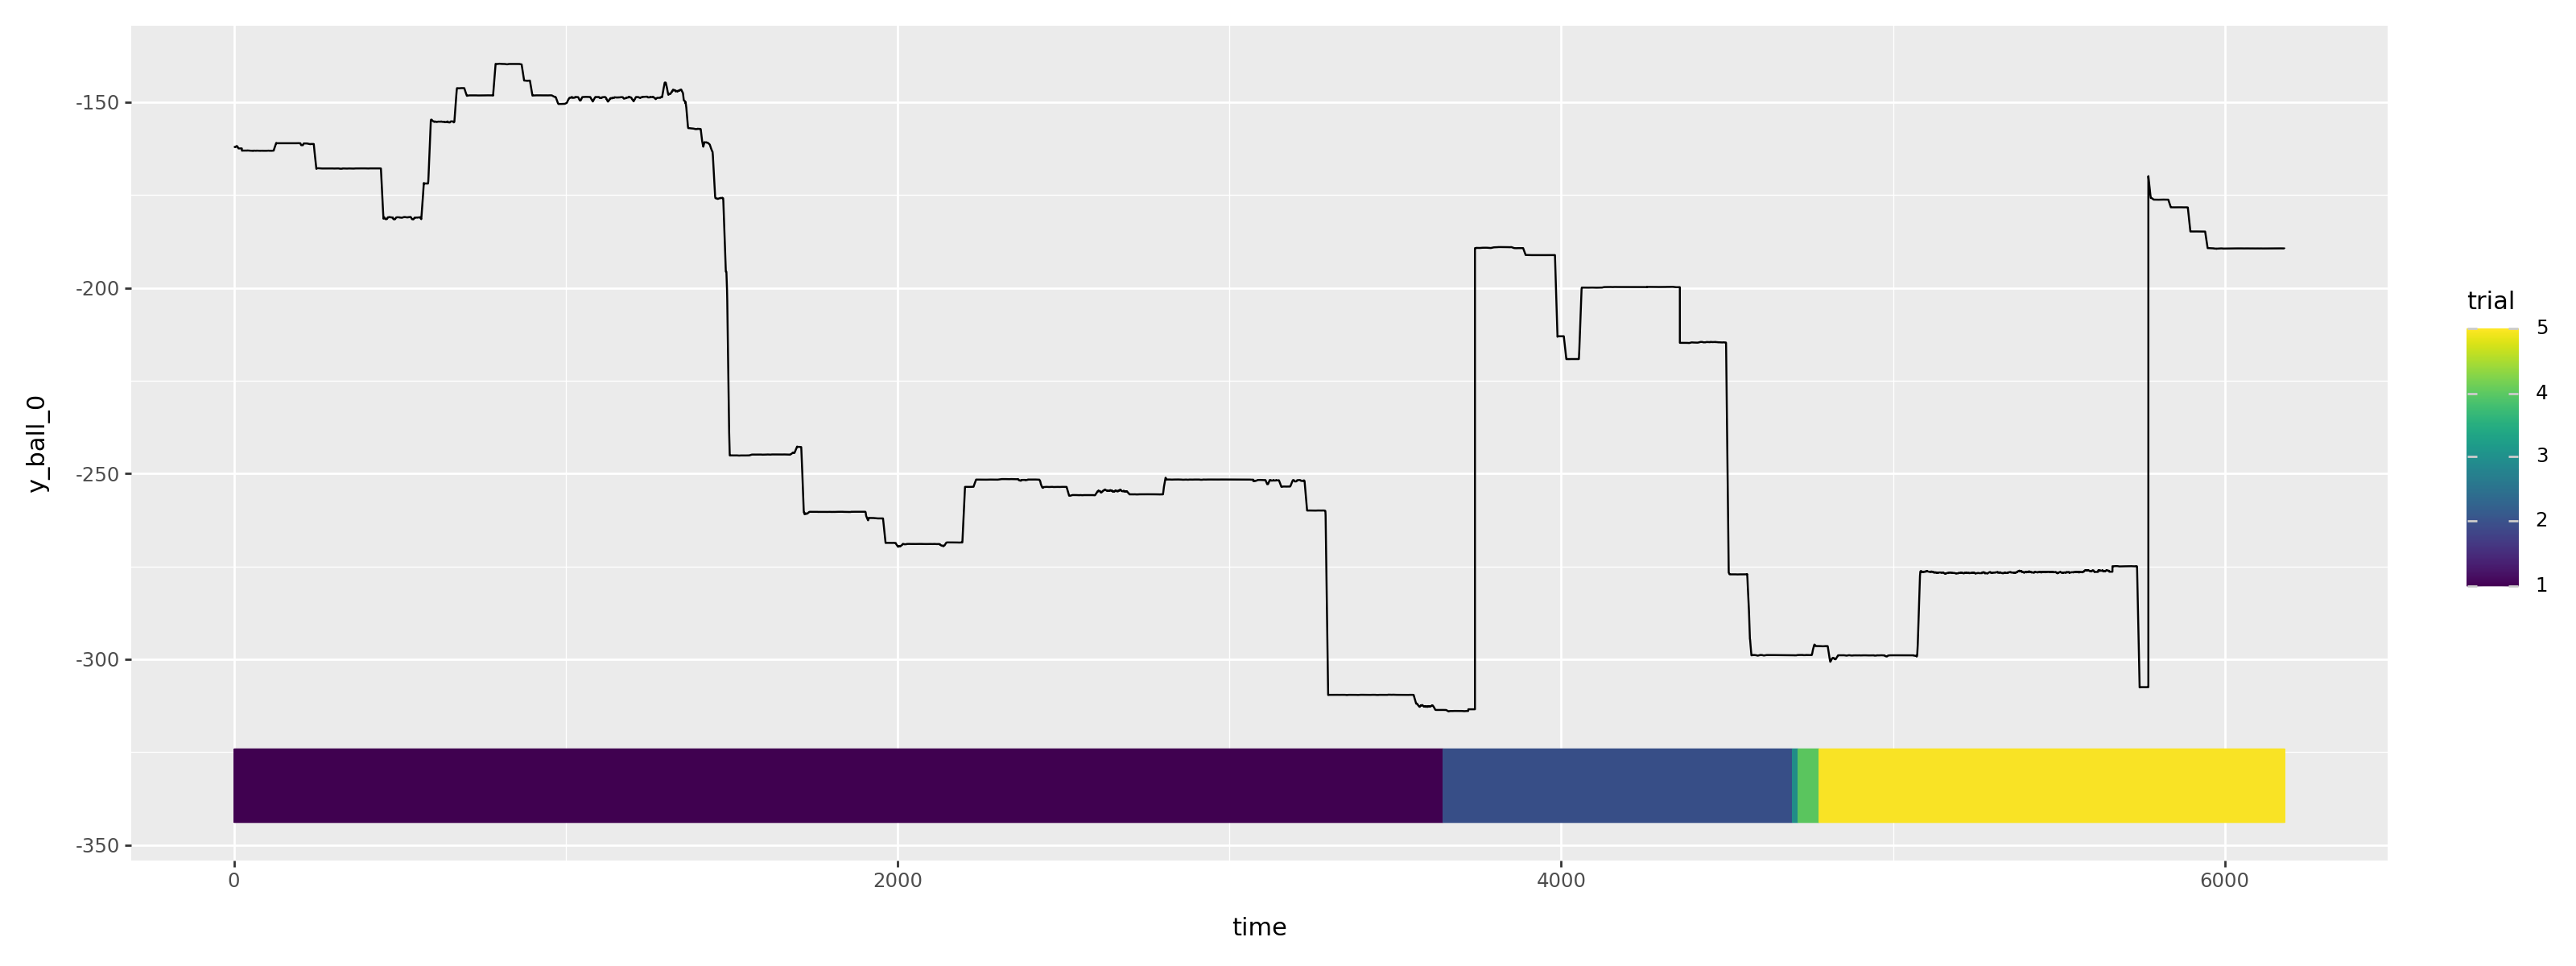

In [61]:
flies = sorted(data.get_column("fly").unique().to_list())


def plot_fly_trials(trial_data: pl.DataFrame):
    return (
        p9.ggplot(
            trial_data.drop_nulls("trial"),
            p9.aes(x="time", y="y_ball_0"),
        )
        + p9.geom_line()
        + p9.geom_tile(p9.aes(x="time", y="min(y_ball_0)-20", color="trial", height=20))
        # + p9.facet_grid(cols="trial", scales="free_x")
        + p9.theme(figure_size=(16, 6))
    )


plot_fly_trials(data.filter(fly=flies[2]))

The first trial looks OK, the second too, the third and fourth are way too short and fifth ends too late

## Try to replicate existing trial detection

Detecting peaks above 50 magnitude seems OK

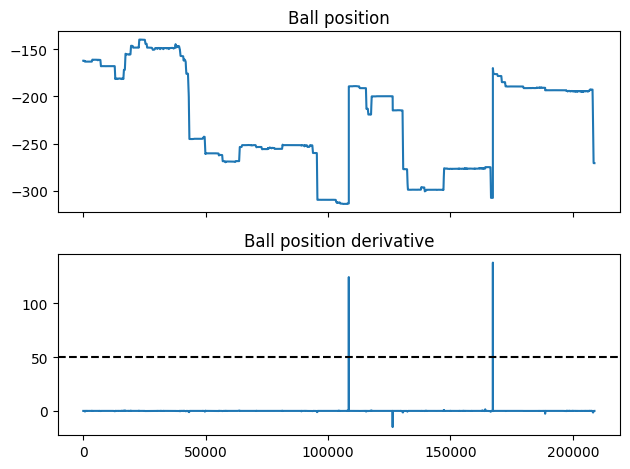

In [76]:
ball_data_trial = data.filter(fly=flies[2]).get_column("y_ball_0")

fig, axs = plt.subplots(2, 1, sharex=True)
axs[0].plot(ball_data_trial)
axs[1].plot(ball_data_trial.diff(5))
axs[1].axhline(50, color="black", ls="--")
axs[0].set_title("Ball position")
axs[1].set_title("Ball position derivative")
plt.tight_layout()
plt.show()

In [ ]:
from scipy.signal import find_peaks


# Copied and adapted from src/ballpushing_utils/learning_metrics.py
def detect_trials(ball_pos_data: pl.Series):
    """
    Detect individual trials based on negative peaks in the ball position derivative.
    """
    # Find large peaks in the ball velocity (indicating ball reset)
    # Compute velocity over a 5 frame window just in case the magnet moved the ball slowly
    peaks, _ = find_peaks(
        ball_pos_data.diff(5),
        height=50,
        distance=200,  # there's one fly that completes trials very fast - 500 is too much
    )

    trial_data = ball_pos_data.to_frame().with_row_index()  # .with_columns(trial=0)

    trial_number = 1
    previous_peak = 0

    trials = np.zeros(len(trial_data))

    for peak in peaks:
        trials[previous_peak : peak + 1] = trial_number
        trial_number += 1
        previous_peak = peak + 1

    # Assign last trial
    trials[previous_peak:] = trial_number

    # Add trial_frame and trial_time columns
    trial_data = (
        trial_data.with_columns(trial=pl.Series(trials))
        .with_columns(trial_frame=pl.int_range(pl.len()).over("trial"))
        .with_columns(trial_time=pl.col("trial_frame") / 29)
        .with_columns(time=pl.col("index") / 29)
    )

    return trial_data

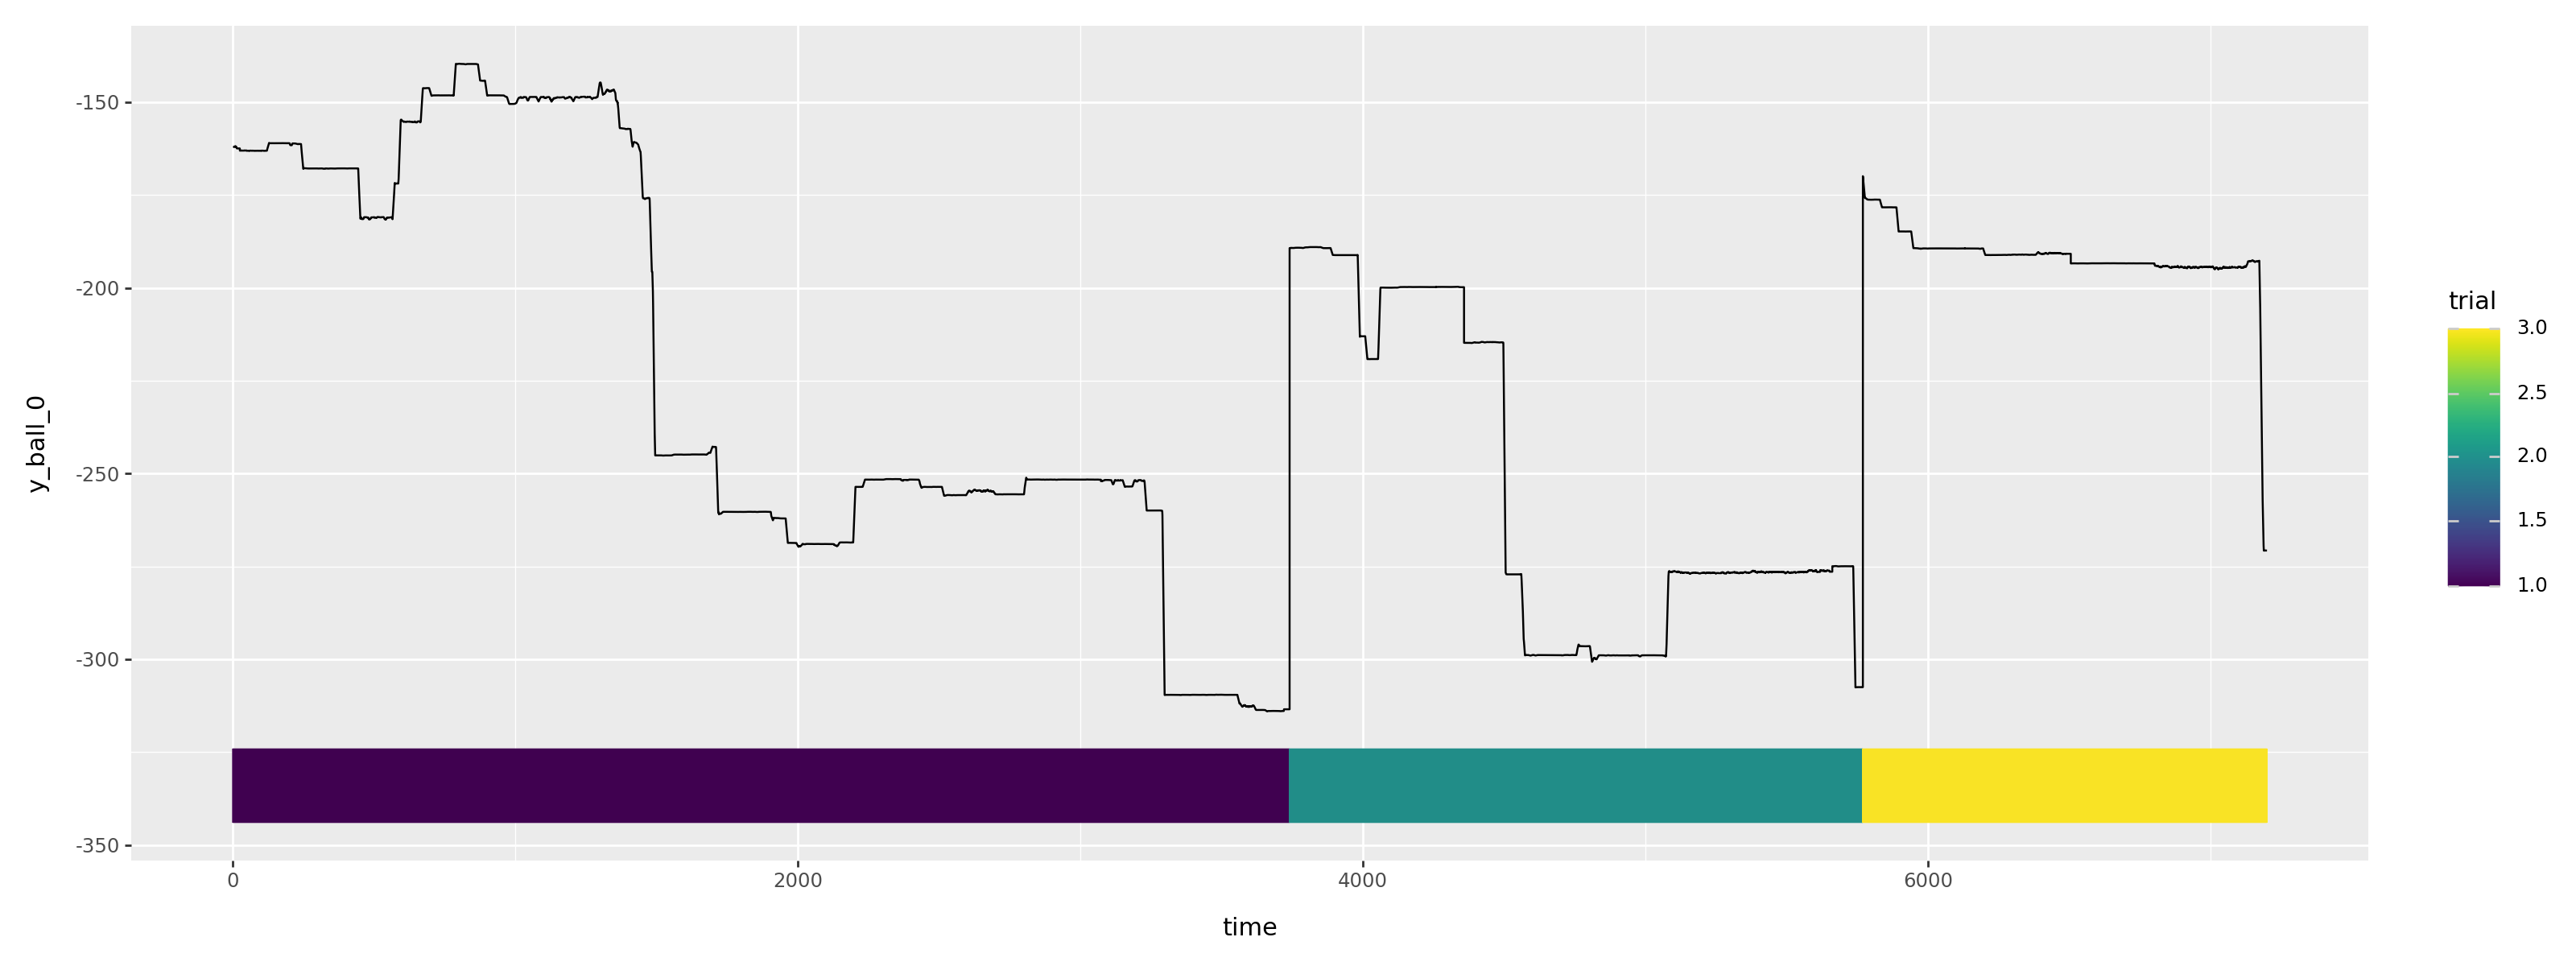

In [78]:
new_data = detect_trials(data.filter(fly=flies[2]).get_column("y_ball_0"))

plot_fly_trials(new_data)

## Test on a bunch of flies

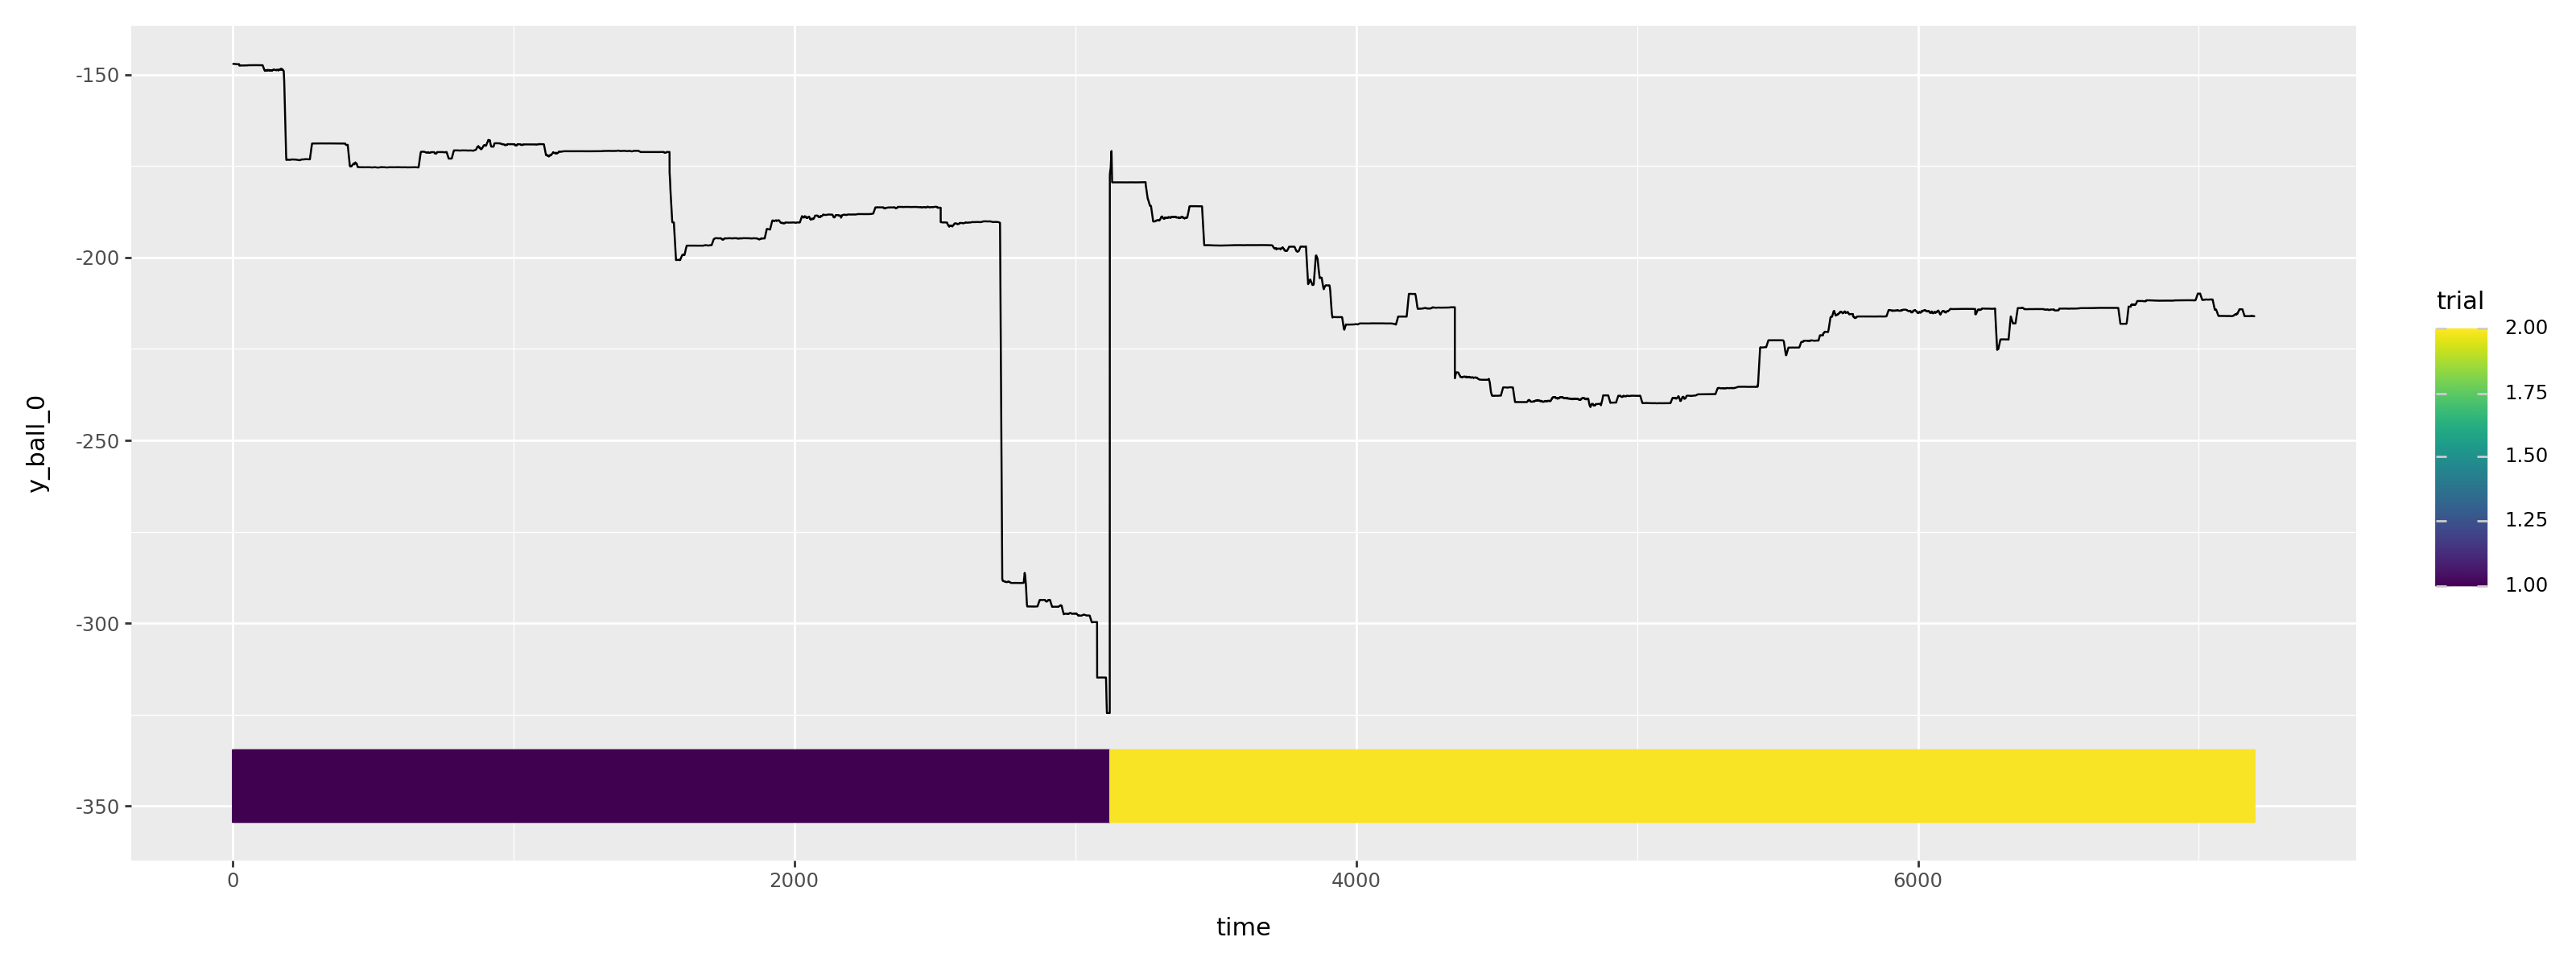

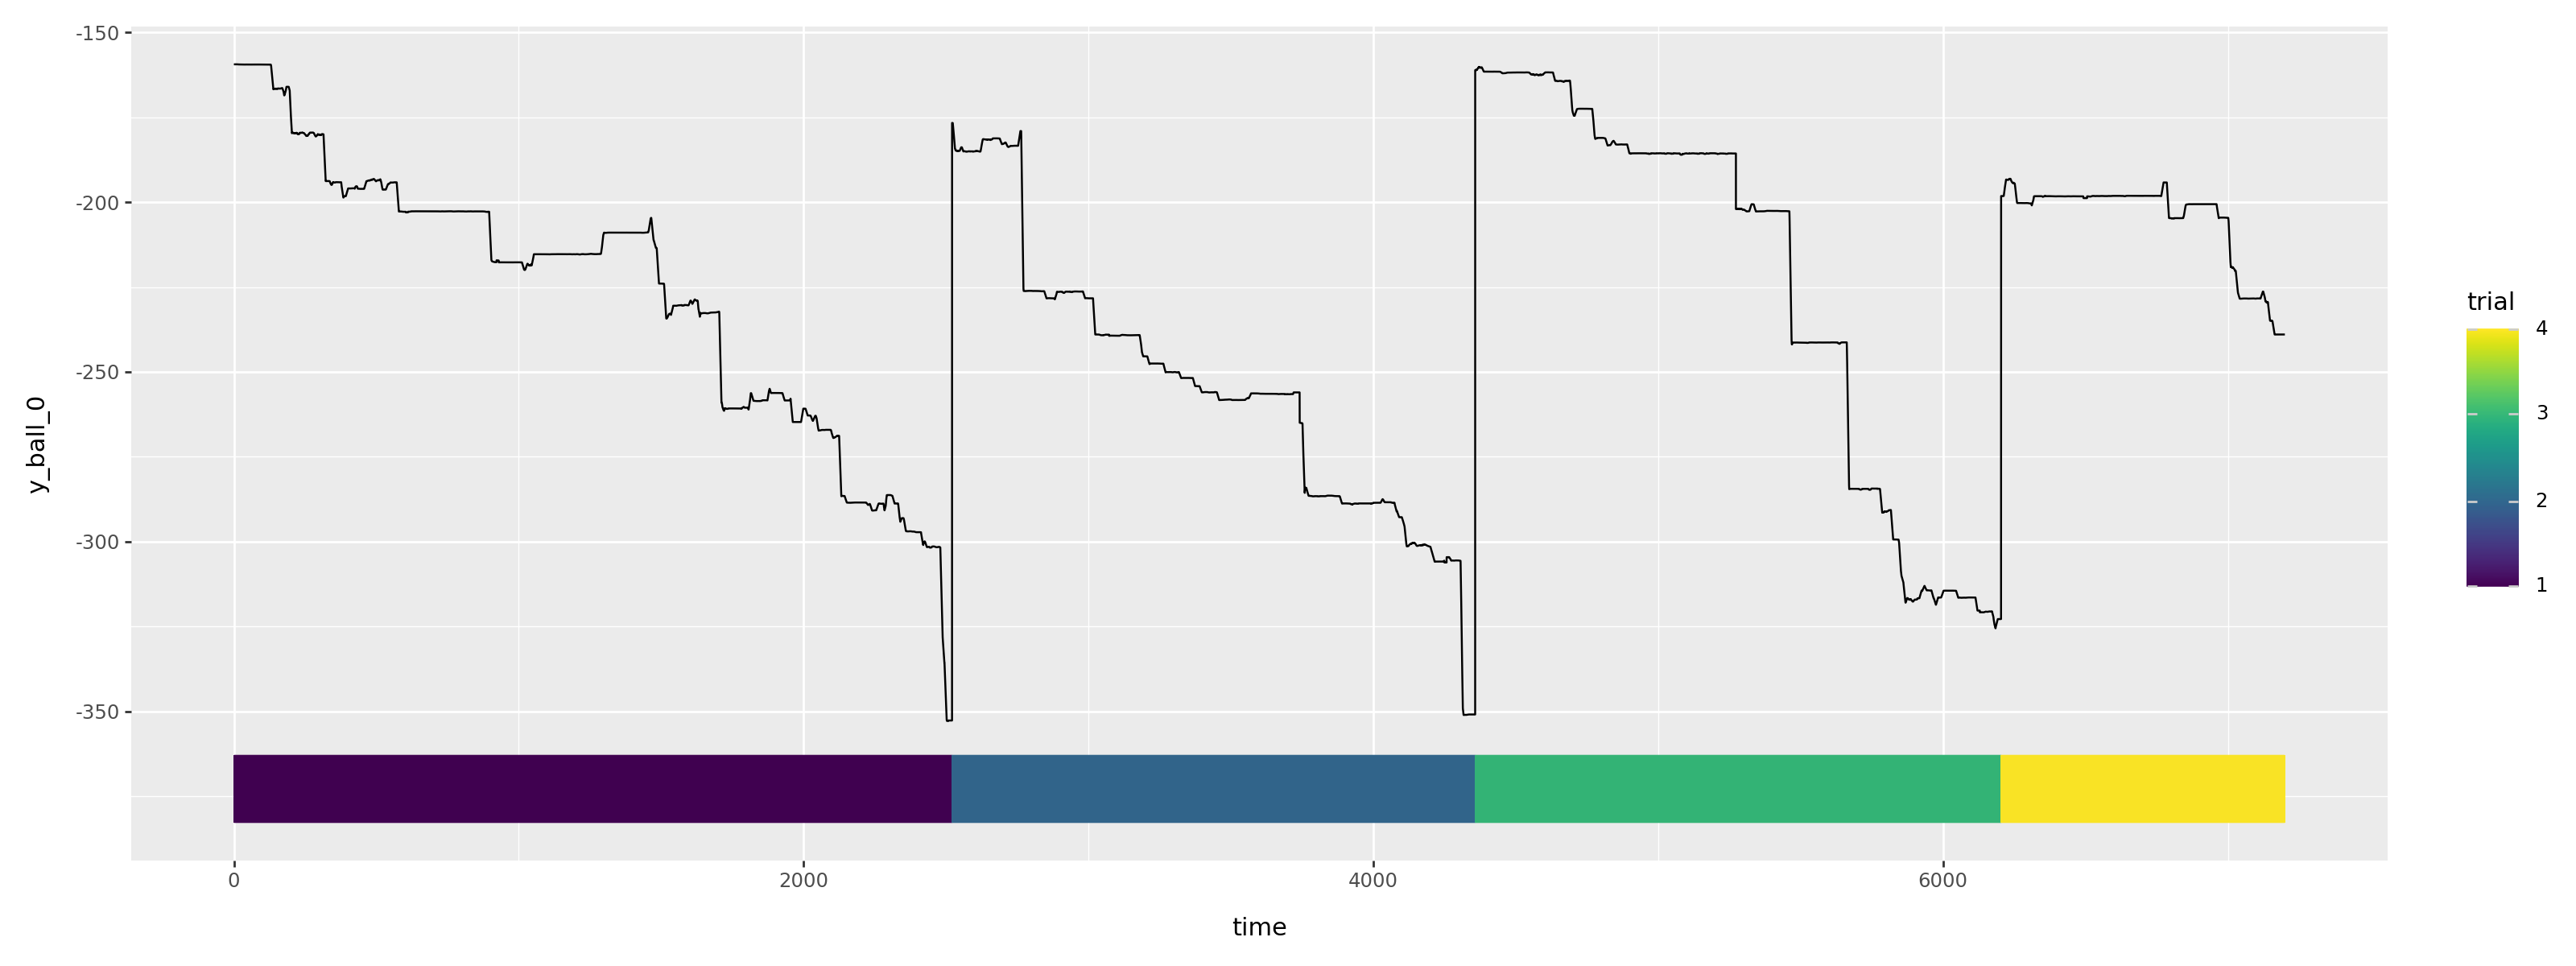

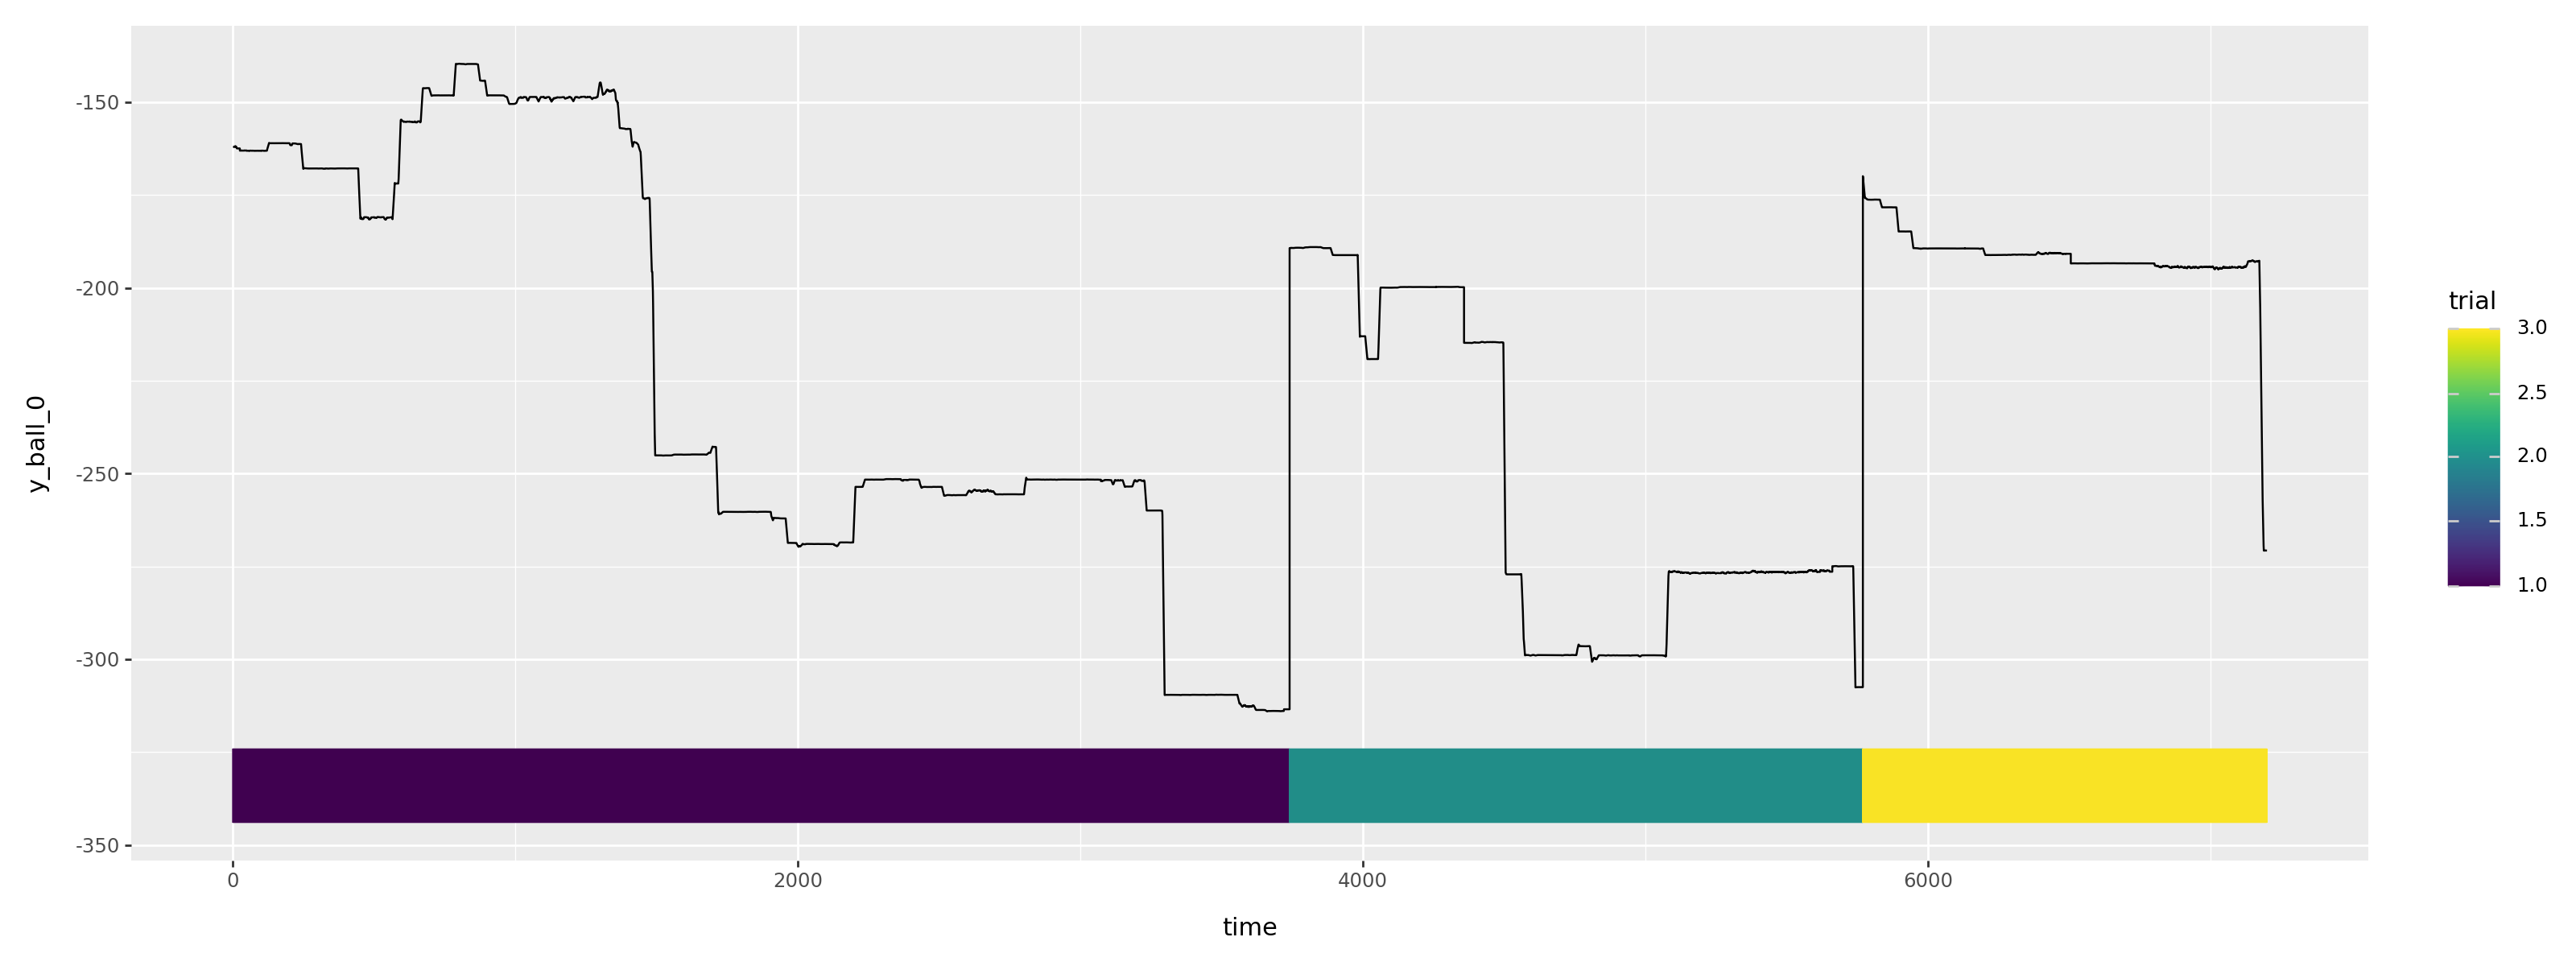

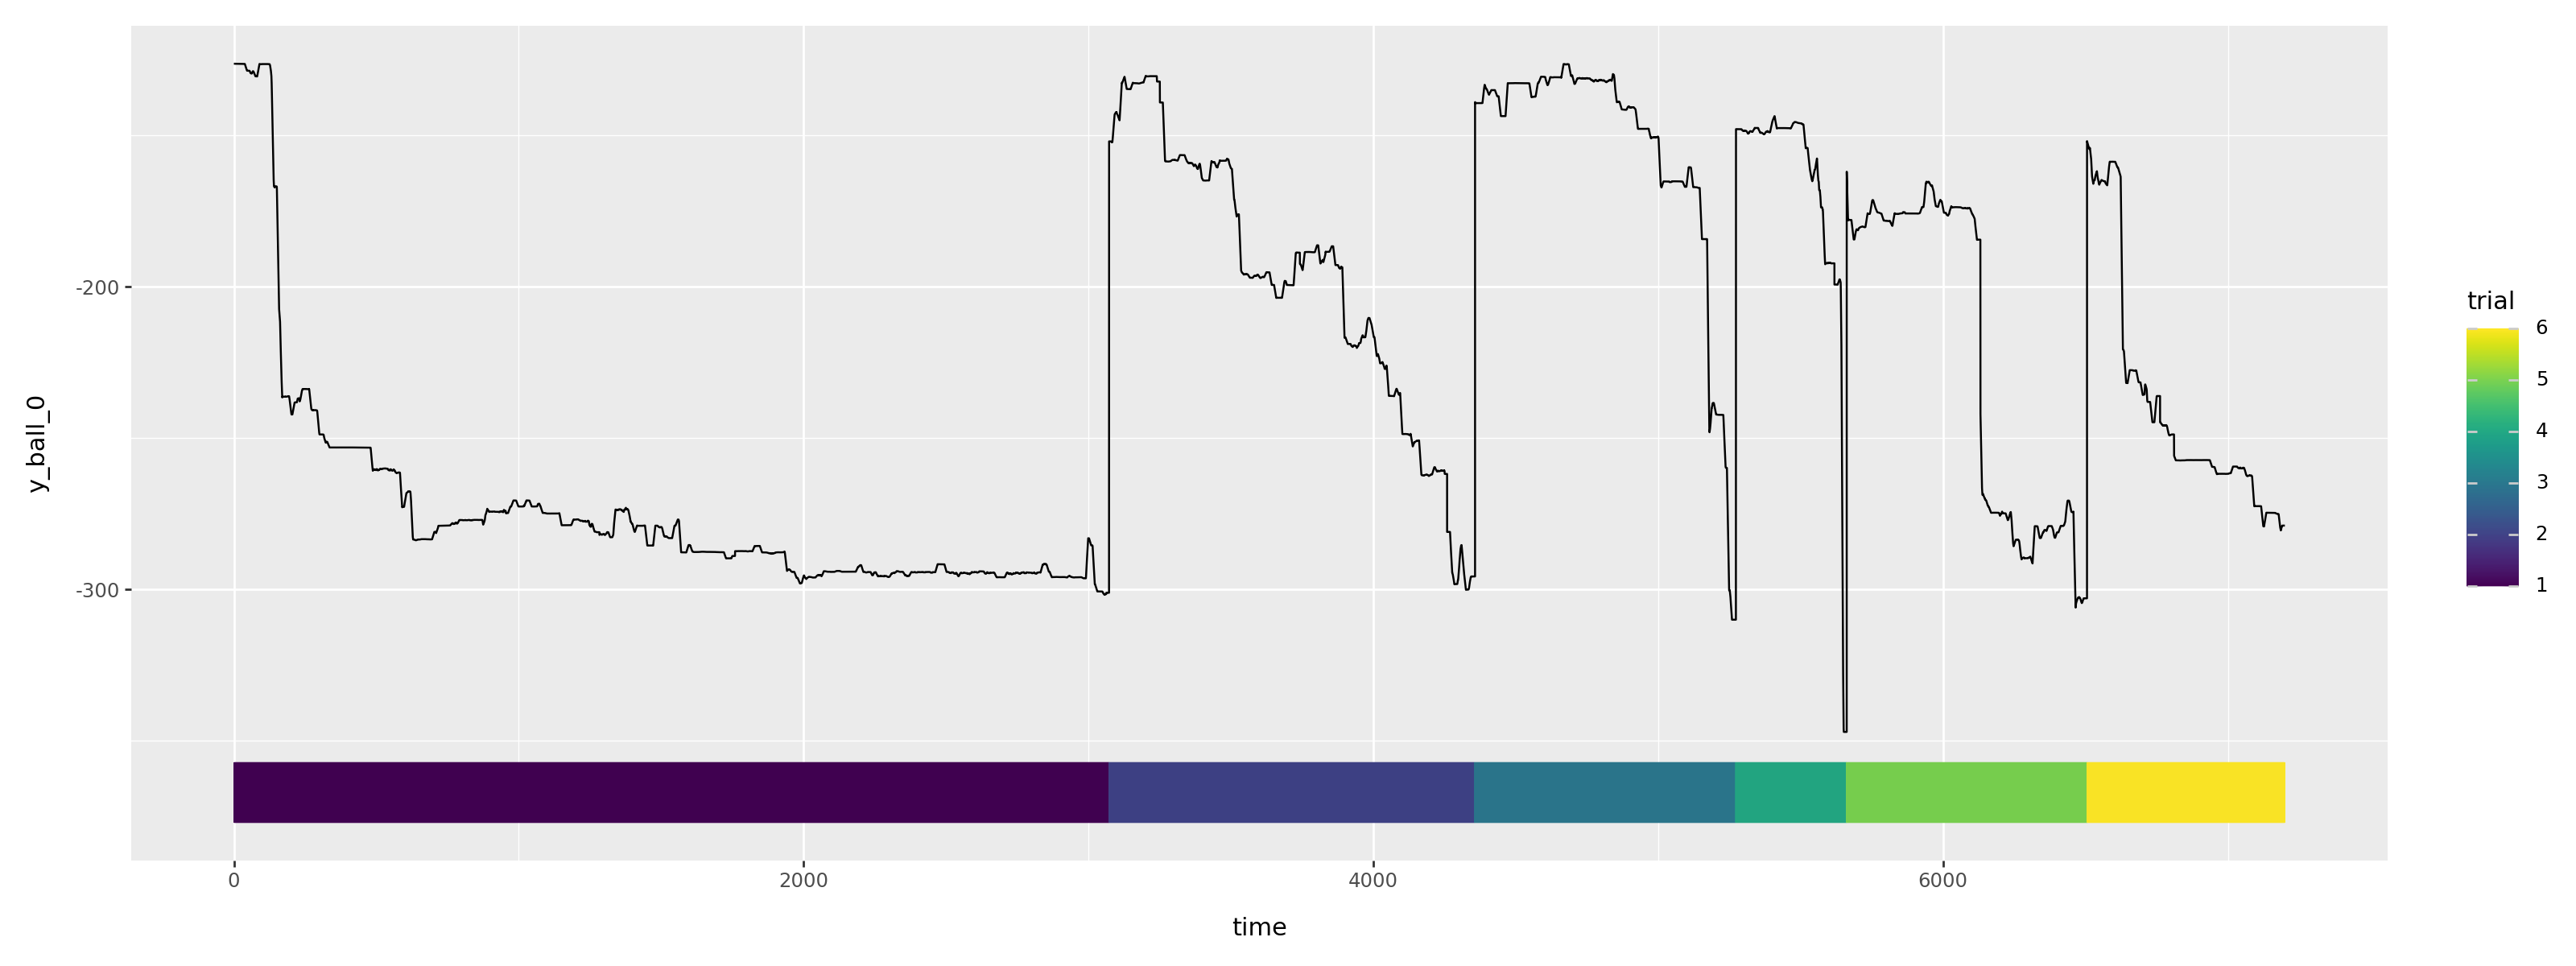

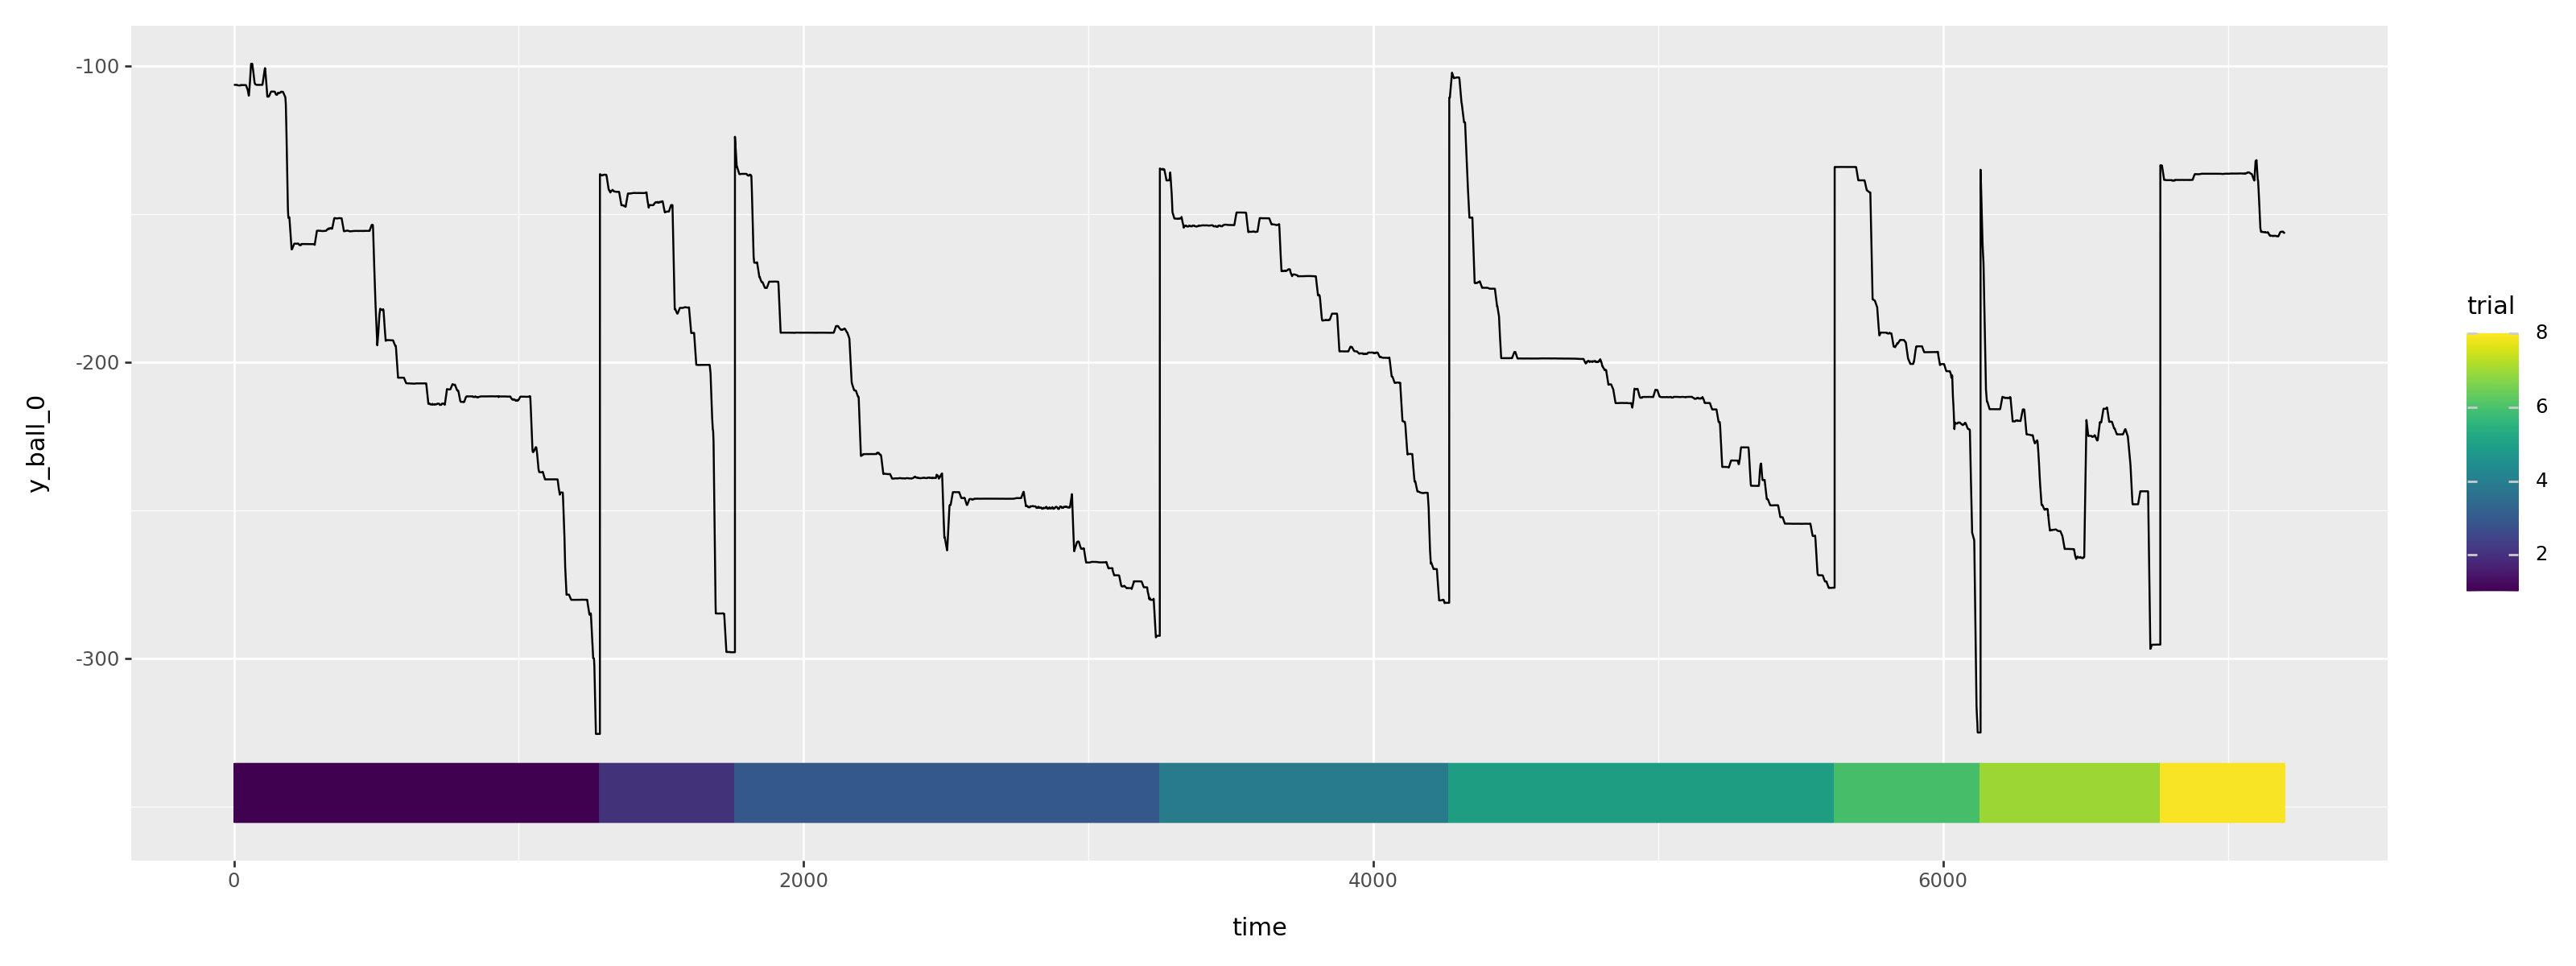

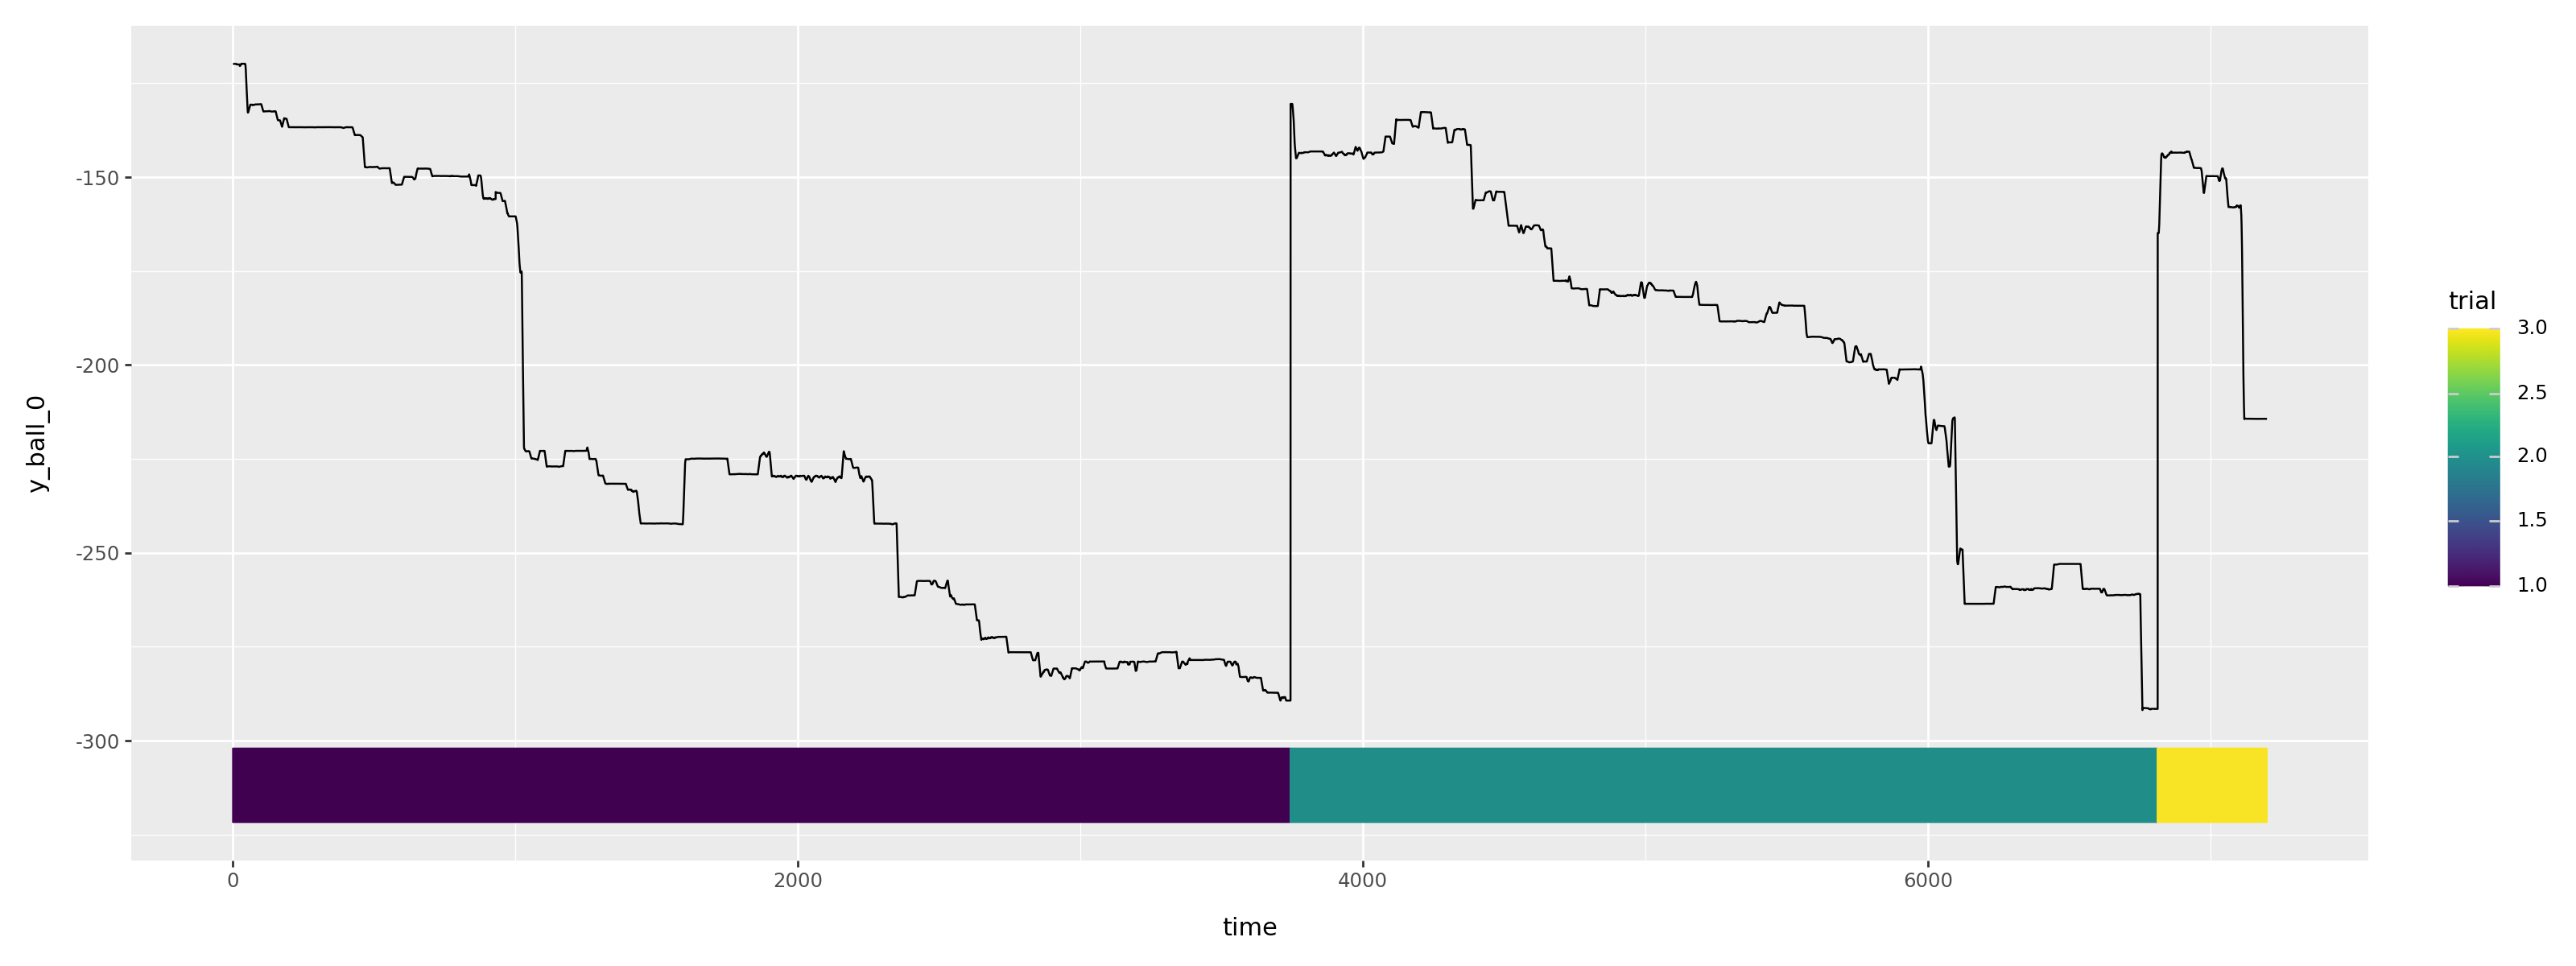

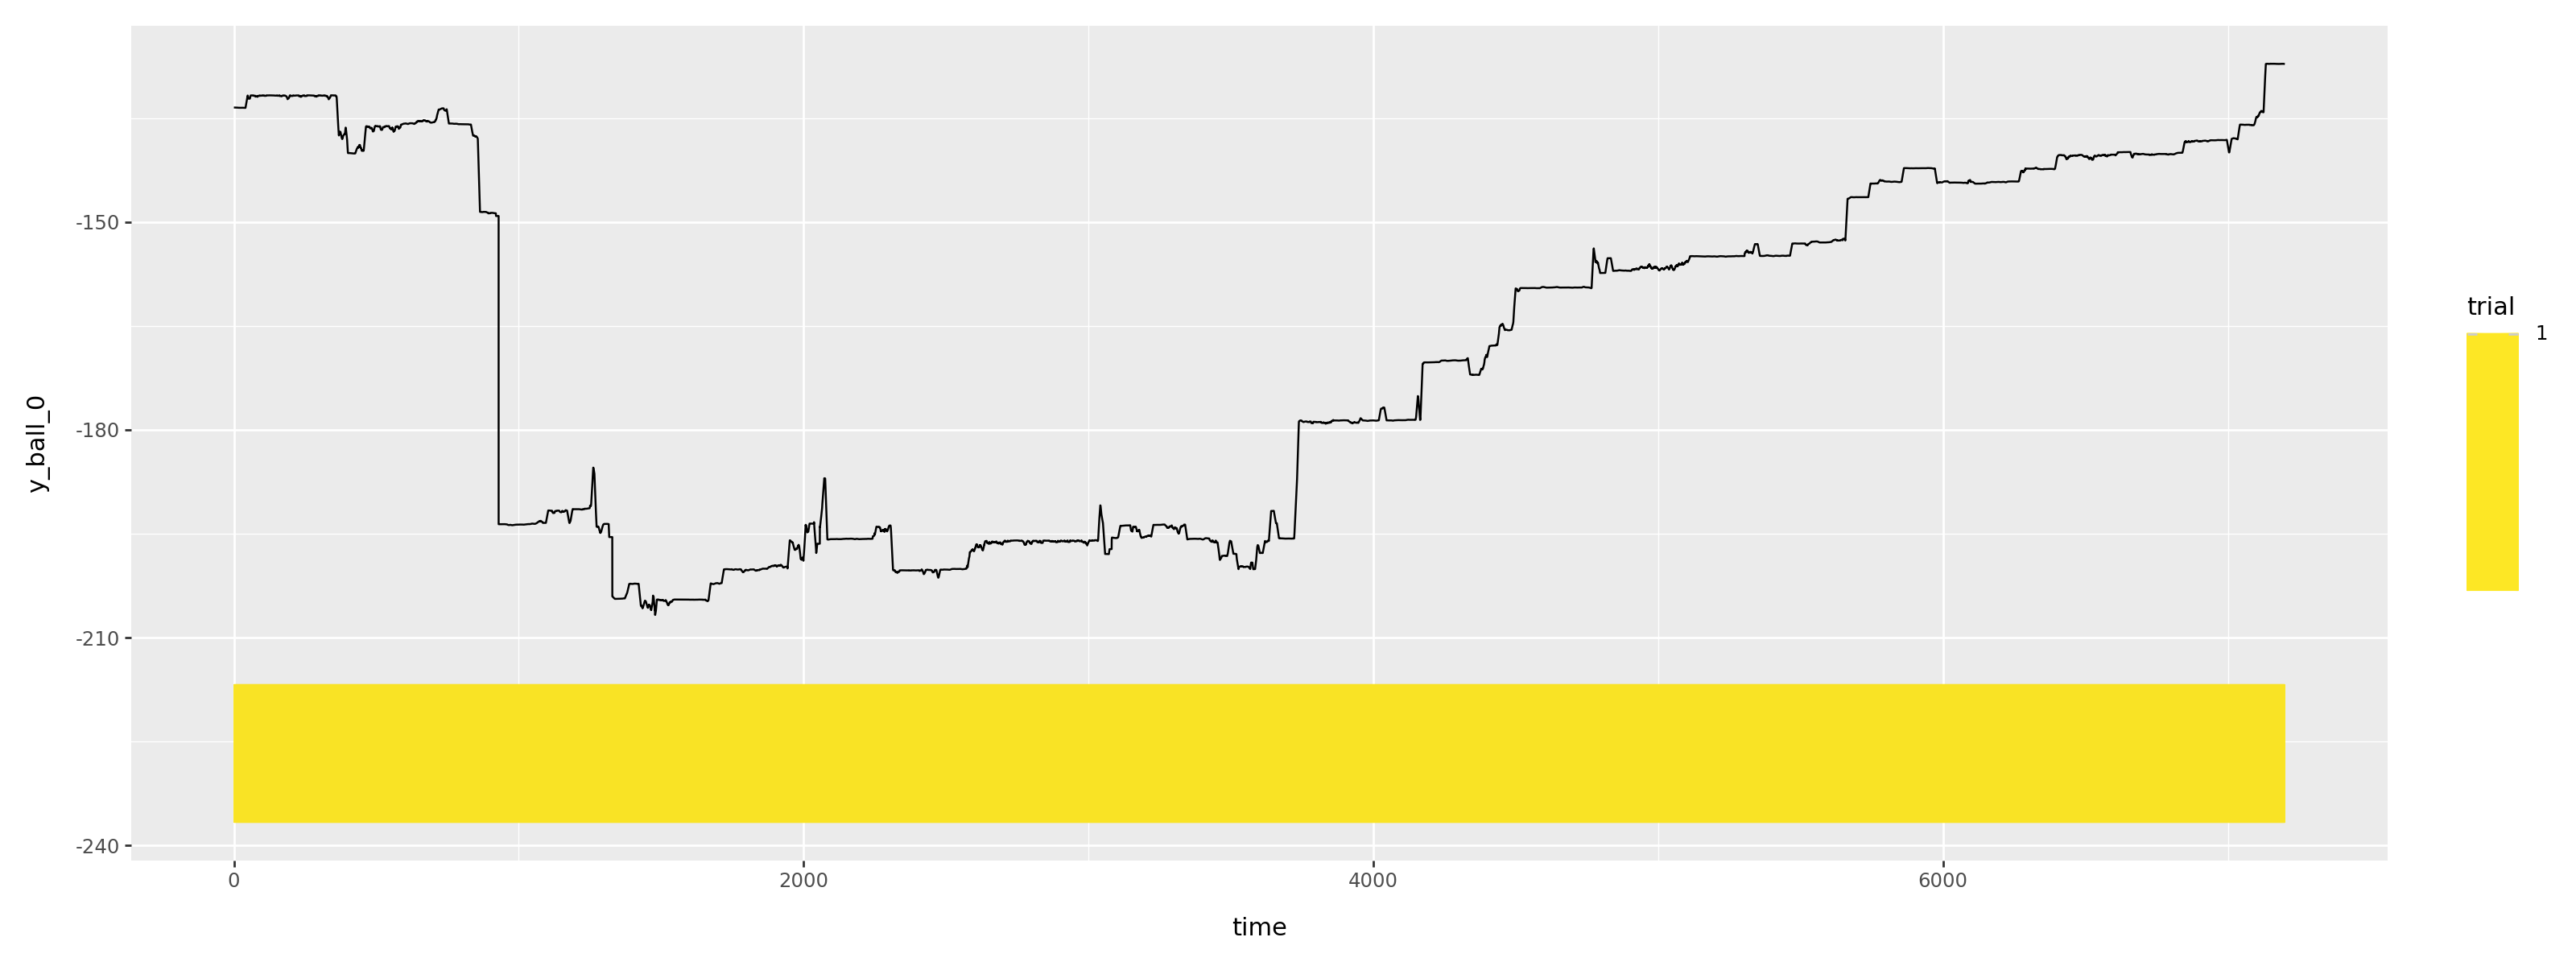

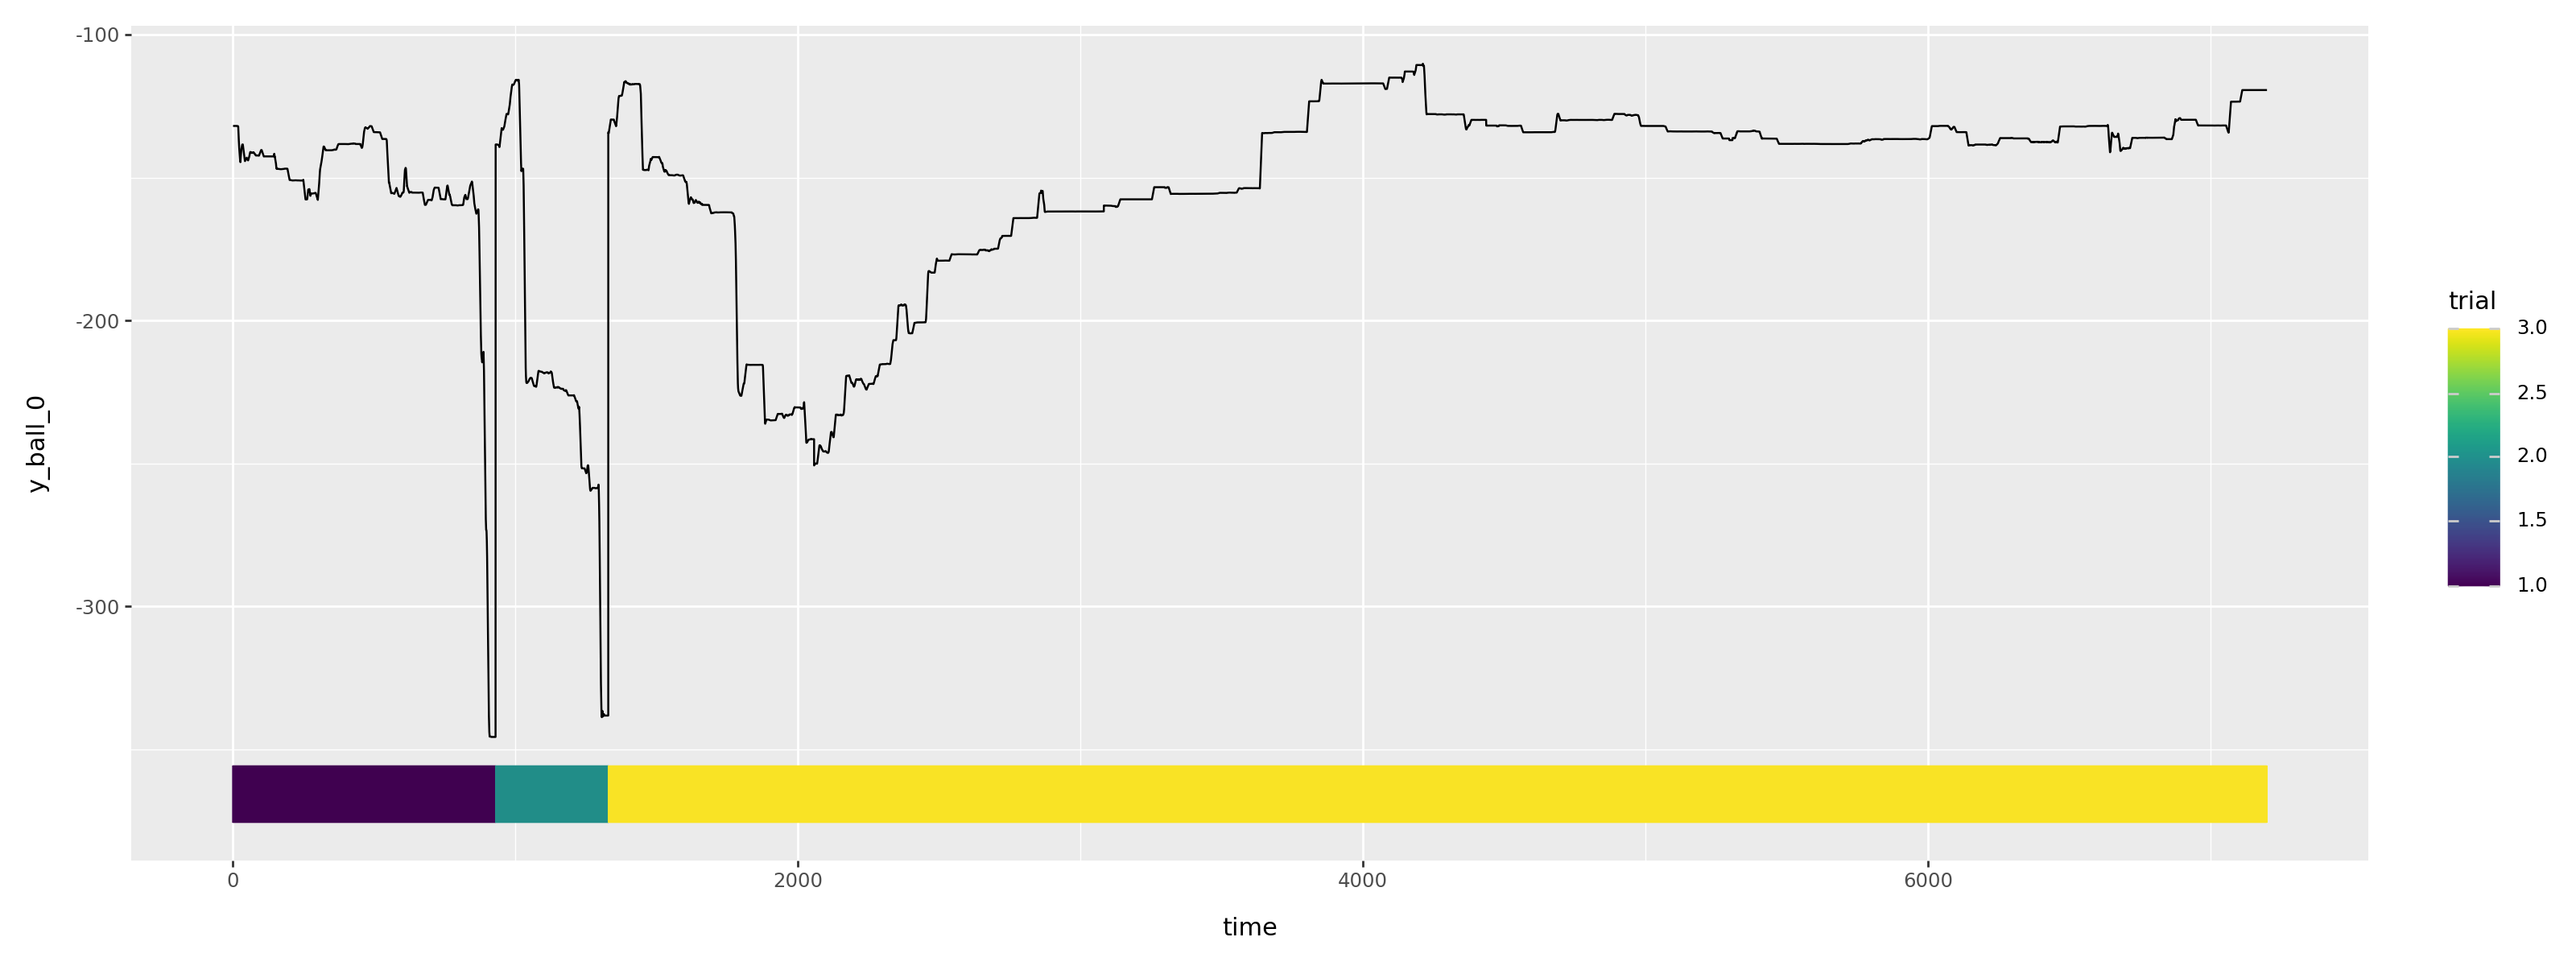

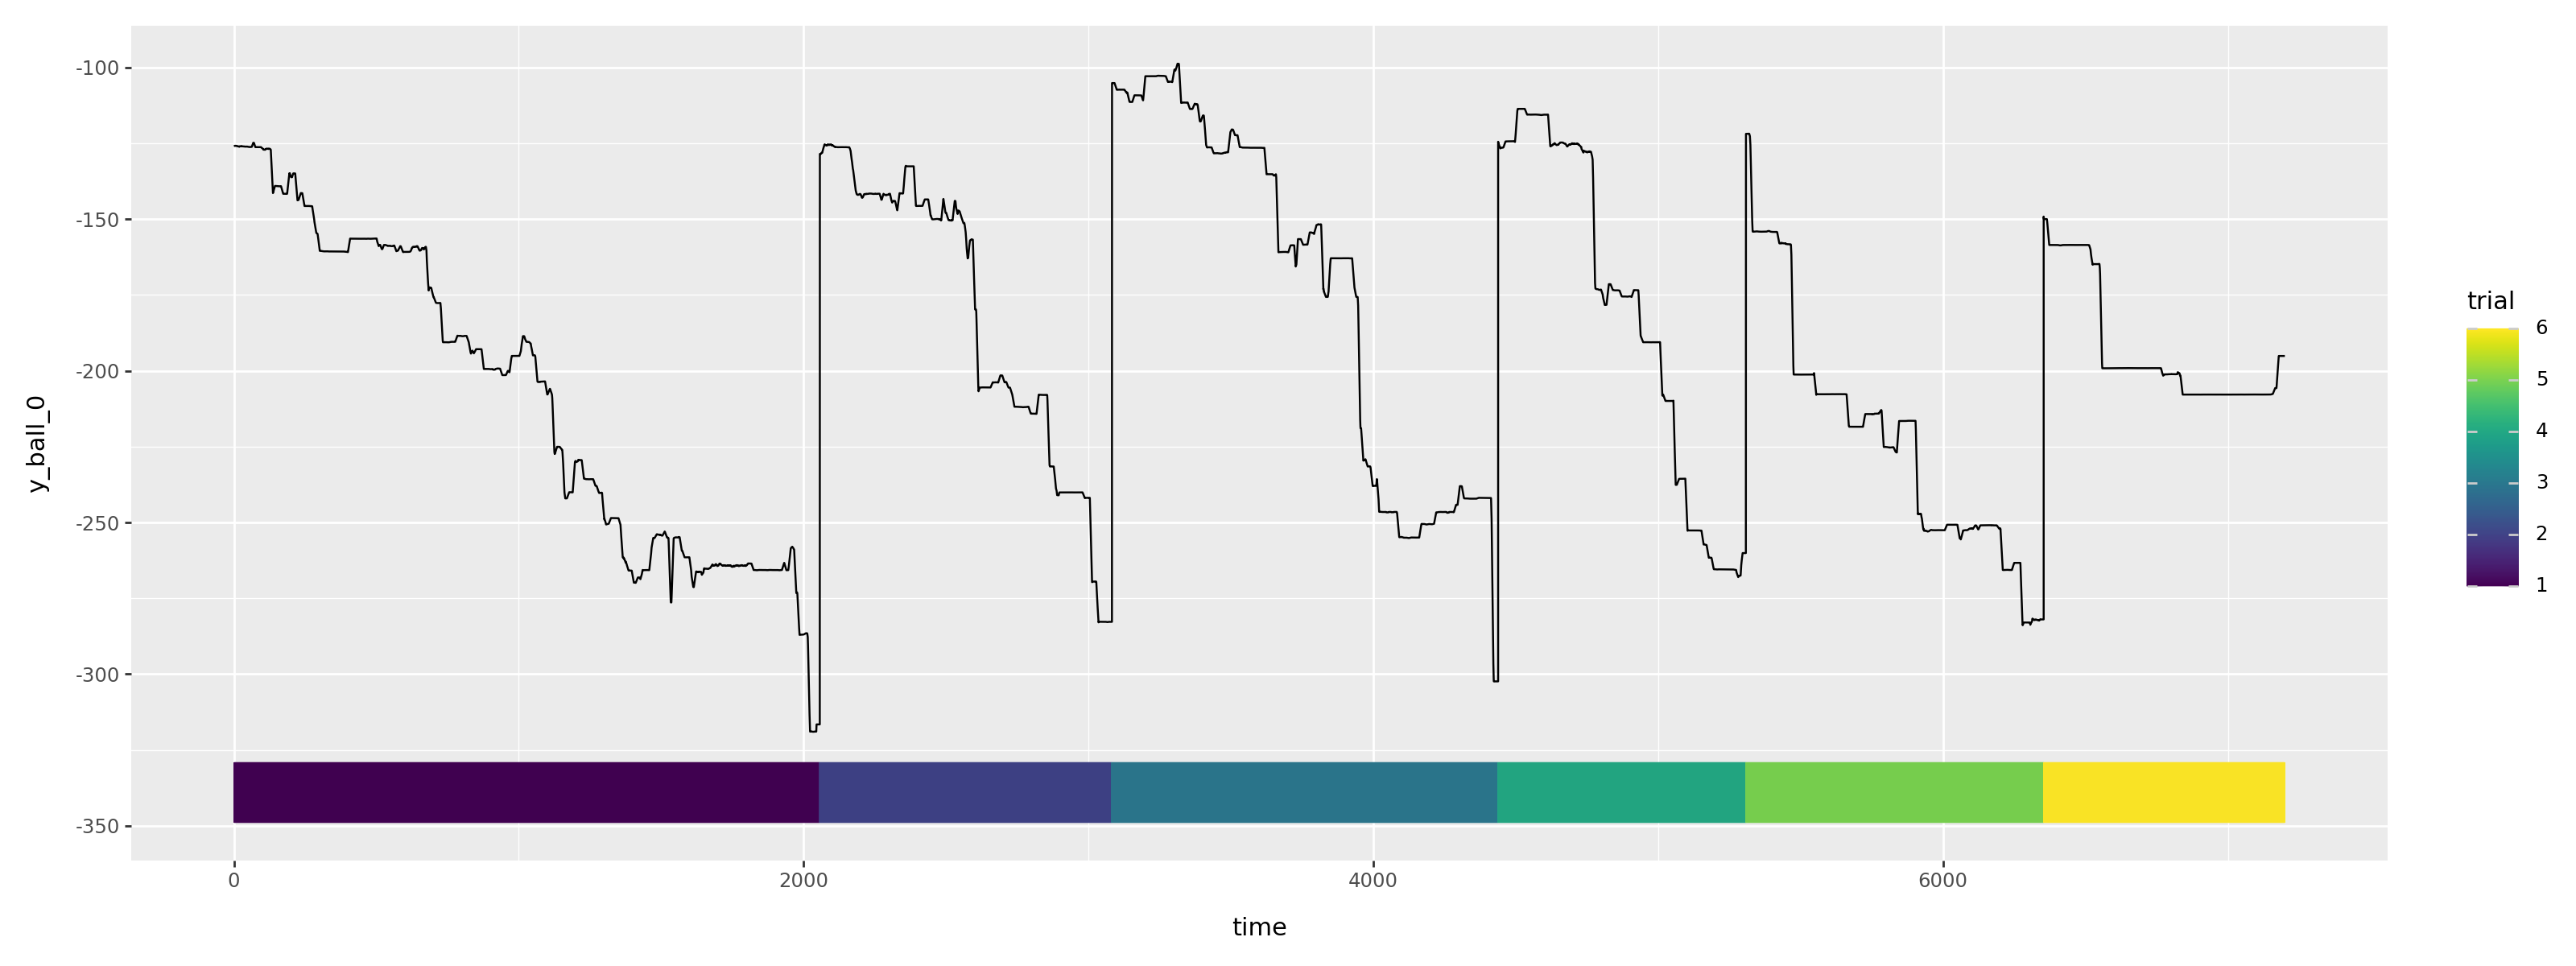

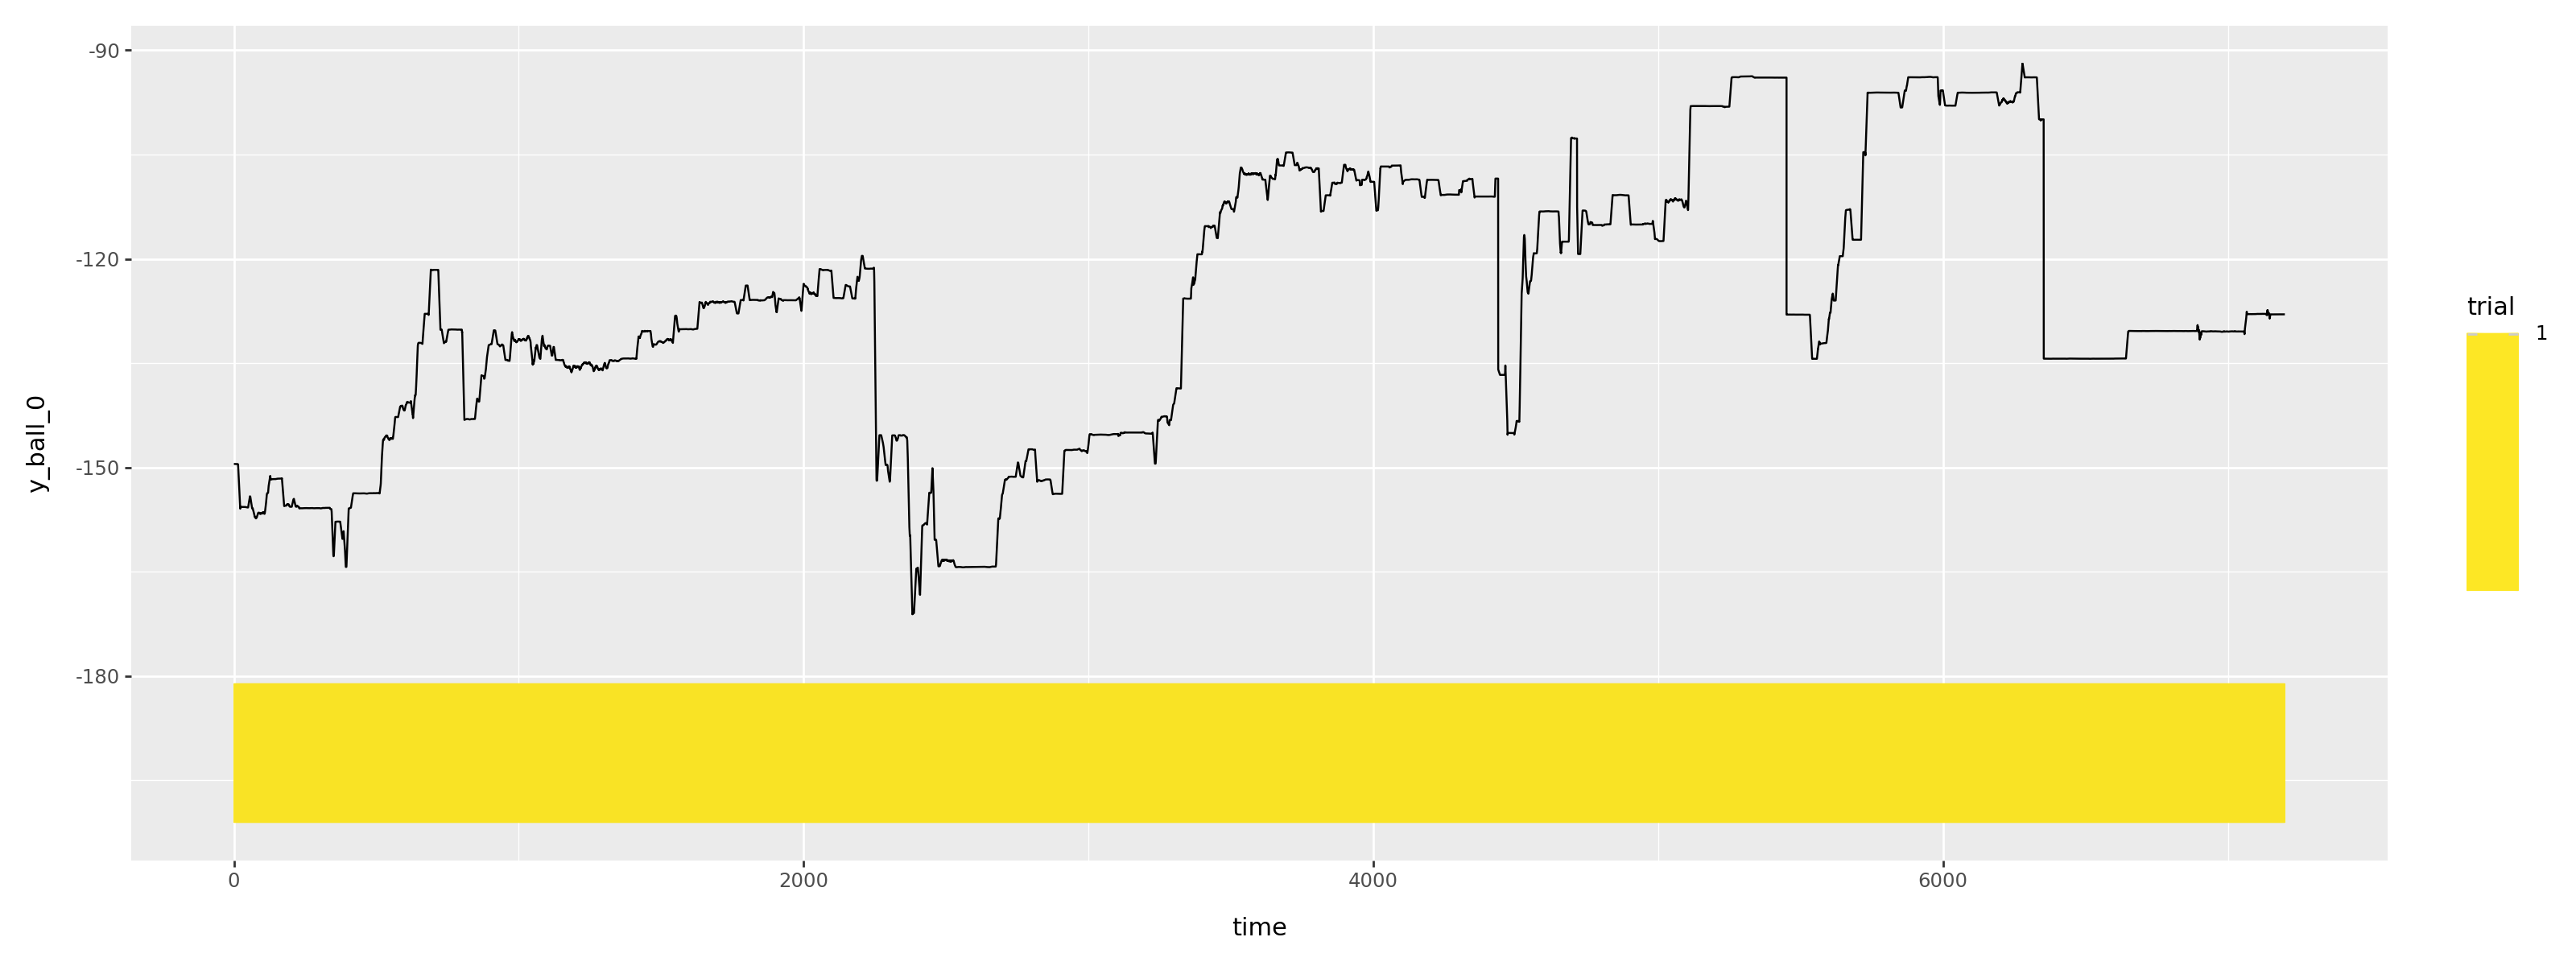

In [79]:
for fly in flies[:10]:
    fly_data_with_trials = detect_trials(data.filter(fly=fly).get_column("y_ball_0"))
    plot_fly_trials(fly_data_with_trials).show()

Looks pretty good!

## Running this for all flies and recomputing results

From above we also notice that the last trial a fly is doing will always be unfinished, so a fly that has completed 4 trials will need to have a maximum trial number of 5

In [108]:
new_data = pl.concat(
    [
        detect_trials(data.filter(fly=fly).get_column("y_ball_0")).with_columns(fly=pl.lit(fly))
        for fly in tqdm.tqdm(flies)
    ]
)
new_data

100%|██████████| 161/161 [00:12<00:00, 13.02it/s]


index,y_ball_0,trial,trial_frame,trial_time,time,fly
u32,f64,f64,i64,f64,f64,str
0,-147.009502,1.0,0,0.0,0.0,"""240717_Learning_Videos_Tracked…"
1,-147.010005,1.0,1,0.034483,0.034483,"""240717_Learning_Videos_Tracked…"
2,-147.010509,1.0,2,0.068966,0.068966,"""240717_Learning_Videos_Tracked…"
3,-147.011012,1.0,3,0.103448,0.103448,"""240717_Learning_Videos_Tracked…"
4,-147.011516,1.0,4,0.137931,0.137931,"""240717_Learning_Videos_Tracked…"
…,…,…,…,…,…,…
208800,-253.632416,3.0,56635,1952.931034,7200.0,"""240726_Learning_Videos_Tracked…"
208801,-253.63201,3.0,56636,1952.965517,7200.034483,"""240726_Learning_Videos_Tracked…"
208802,-253.631604,3.0,56637,1953.0,7200.068966,"""240726_Learning_Videos_Tracked…"


In [109]:
for num_trials in range(1, 6):
    print(
        f"{new_data.filter(pl.n_unique('trial').over('fly') > num_trials).n_unique('fly')}/{new_data.n_unique('fly')} flies completed at least {num_trials} trials"
    )

75/161 flies completed at least 1 trials
45/161 flies completed at least 2 trials
27/161 flies completed at least 3 trials
16/161 flies completed at least 4 trials
12/161 flies completed at least 5 trials


Trying for a few different numbers of trials, we see:
* the second trial is faster than the first
* the third trial is similar to the second
* the fourth trial is similar to the third, but a handful of flies have a very long last trial

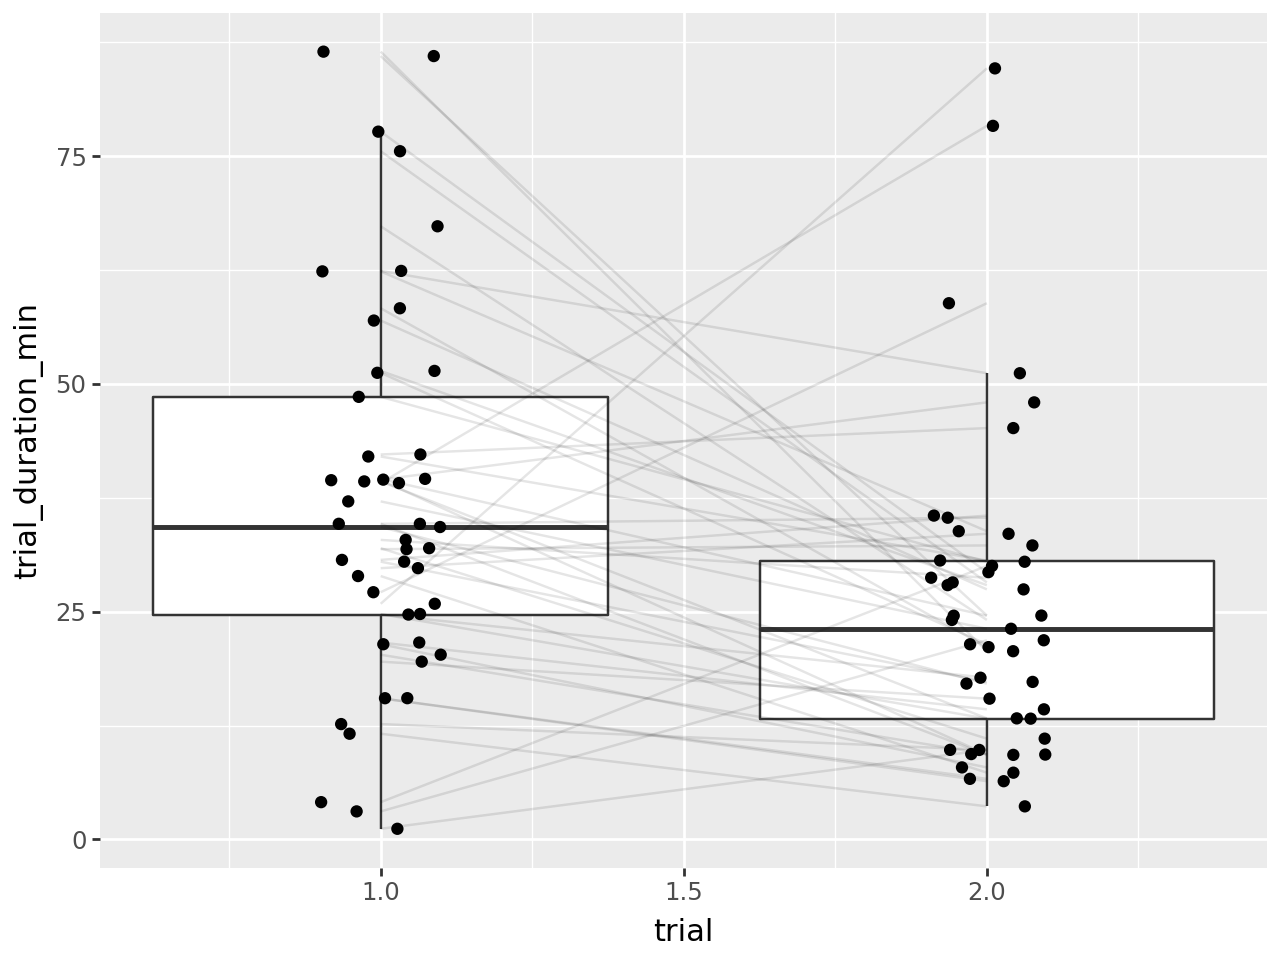

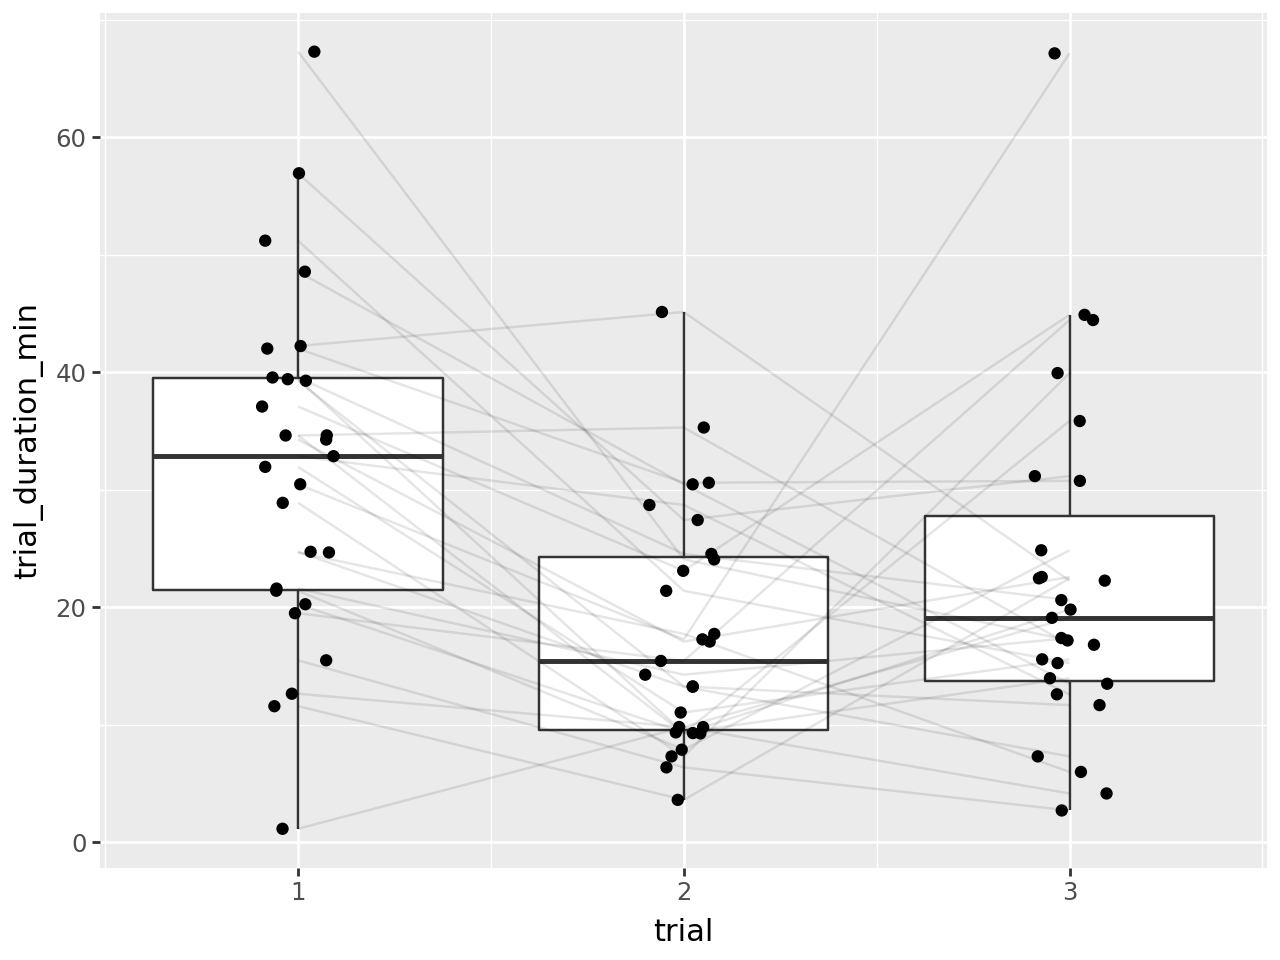

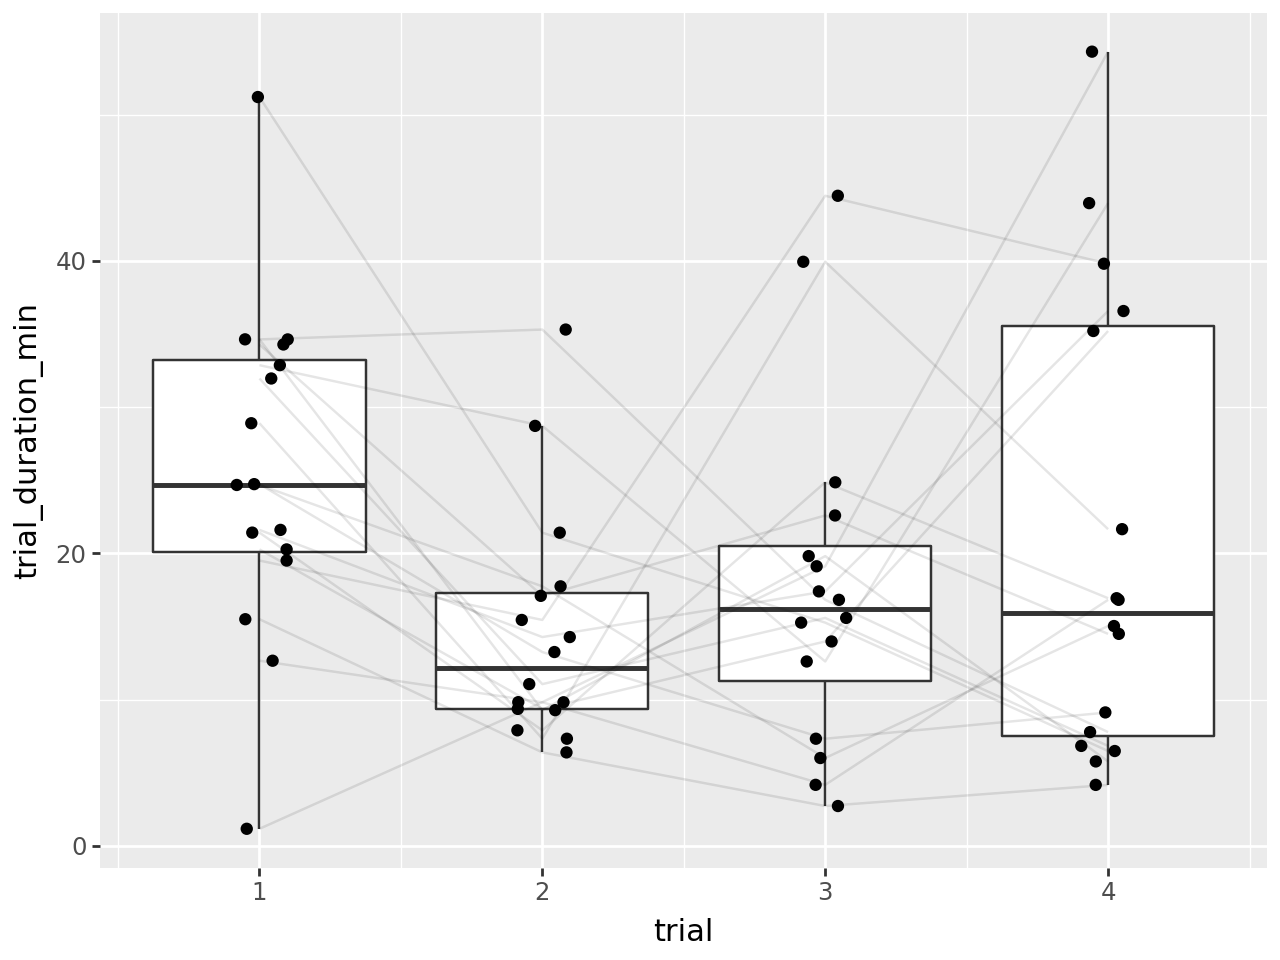

In [110]:
for trials_up_to in range(2, 5):
    trial_durations = (
        new_data.filter(pl.n_unique("trial").over("fly") > trials_up_to)
        .filter(pl.col("trial") <= trials_up_to)
        .group_by("fly", "trial")
        .agg(trial_duration_min=1 / 60 * (pl.col("trial_time").max() - pl.col("trial_time").min()))
    )
    display(plot_trial_durations(trial_durations))

## What if we keep all completed trials from all flies

If we remove the last (unfinished) trial from all flies, we can check the trial durations for all flies. It seems unlikely that case we could somehow be introducing a bias by only selecting the flies that learn well enough to complete N trials, but one reviewer asked for this

Using this method doesn't change the conclusion though - trial 2 is faster than trial 1, but trials 2+ are similar

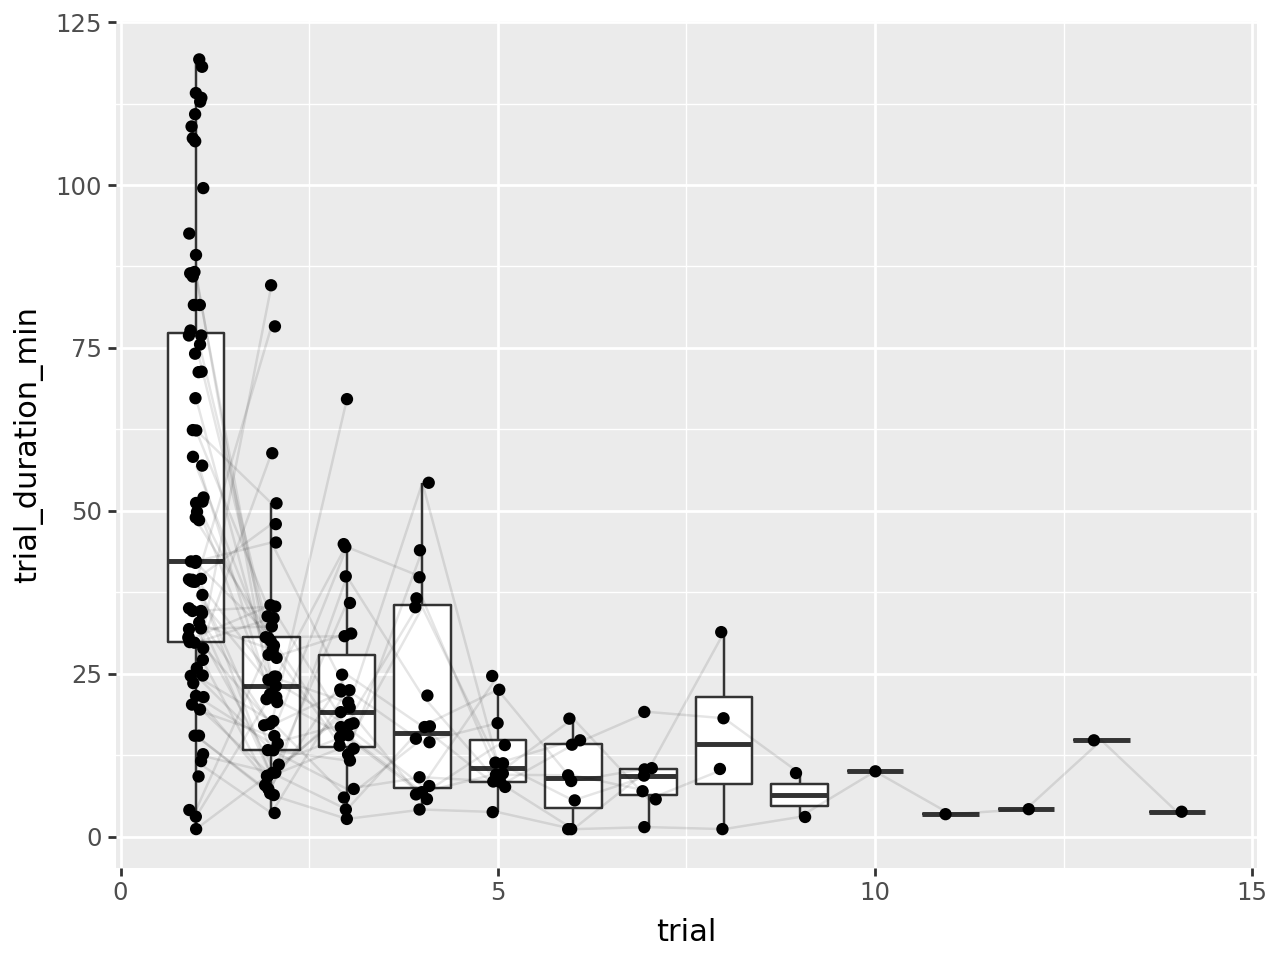

In [111]:
new_data_completed_trials = new_data.filter((pl.col("trial") != pl.col("trial").max()).over("fly"))

plot_trial_durations(
    new_data_completed_trials.group_by("fly", "trial").agg(
        trial_duration_min=1 / 60 * (pl.col("trial_time").max() - pl.col("trial_time").min())
    )
)

## What do the worst and best flies look like?

The best fly pushes very fast - it's hard to know exactly what's going on with it

In [ ]:
completed_trials = (
    new_data.group_by("fly").agg(completed_trials=pl.n_unique("trial") - 1).sort("completed_trials", descending=True)
)
completed_trials

fly,completed_trials
str,u32
"""240723_Learning_Videos_Tracked…",14
"""240726_Learning_Videos_Tracked…",9
"""240726_Learning_Videos_Tracked…",8
"""240717_Learning_Videos_Tracked…",8
"""240717_Learning_Videos_Tracked…",7
…,…
"""240723_Learning_Videos_Tracked…",0
"""240723_Learning_Videos_Tracked…",0
"""240717_Learning_Videos_Tracked…",0


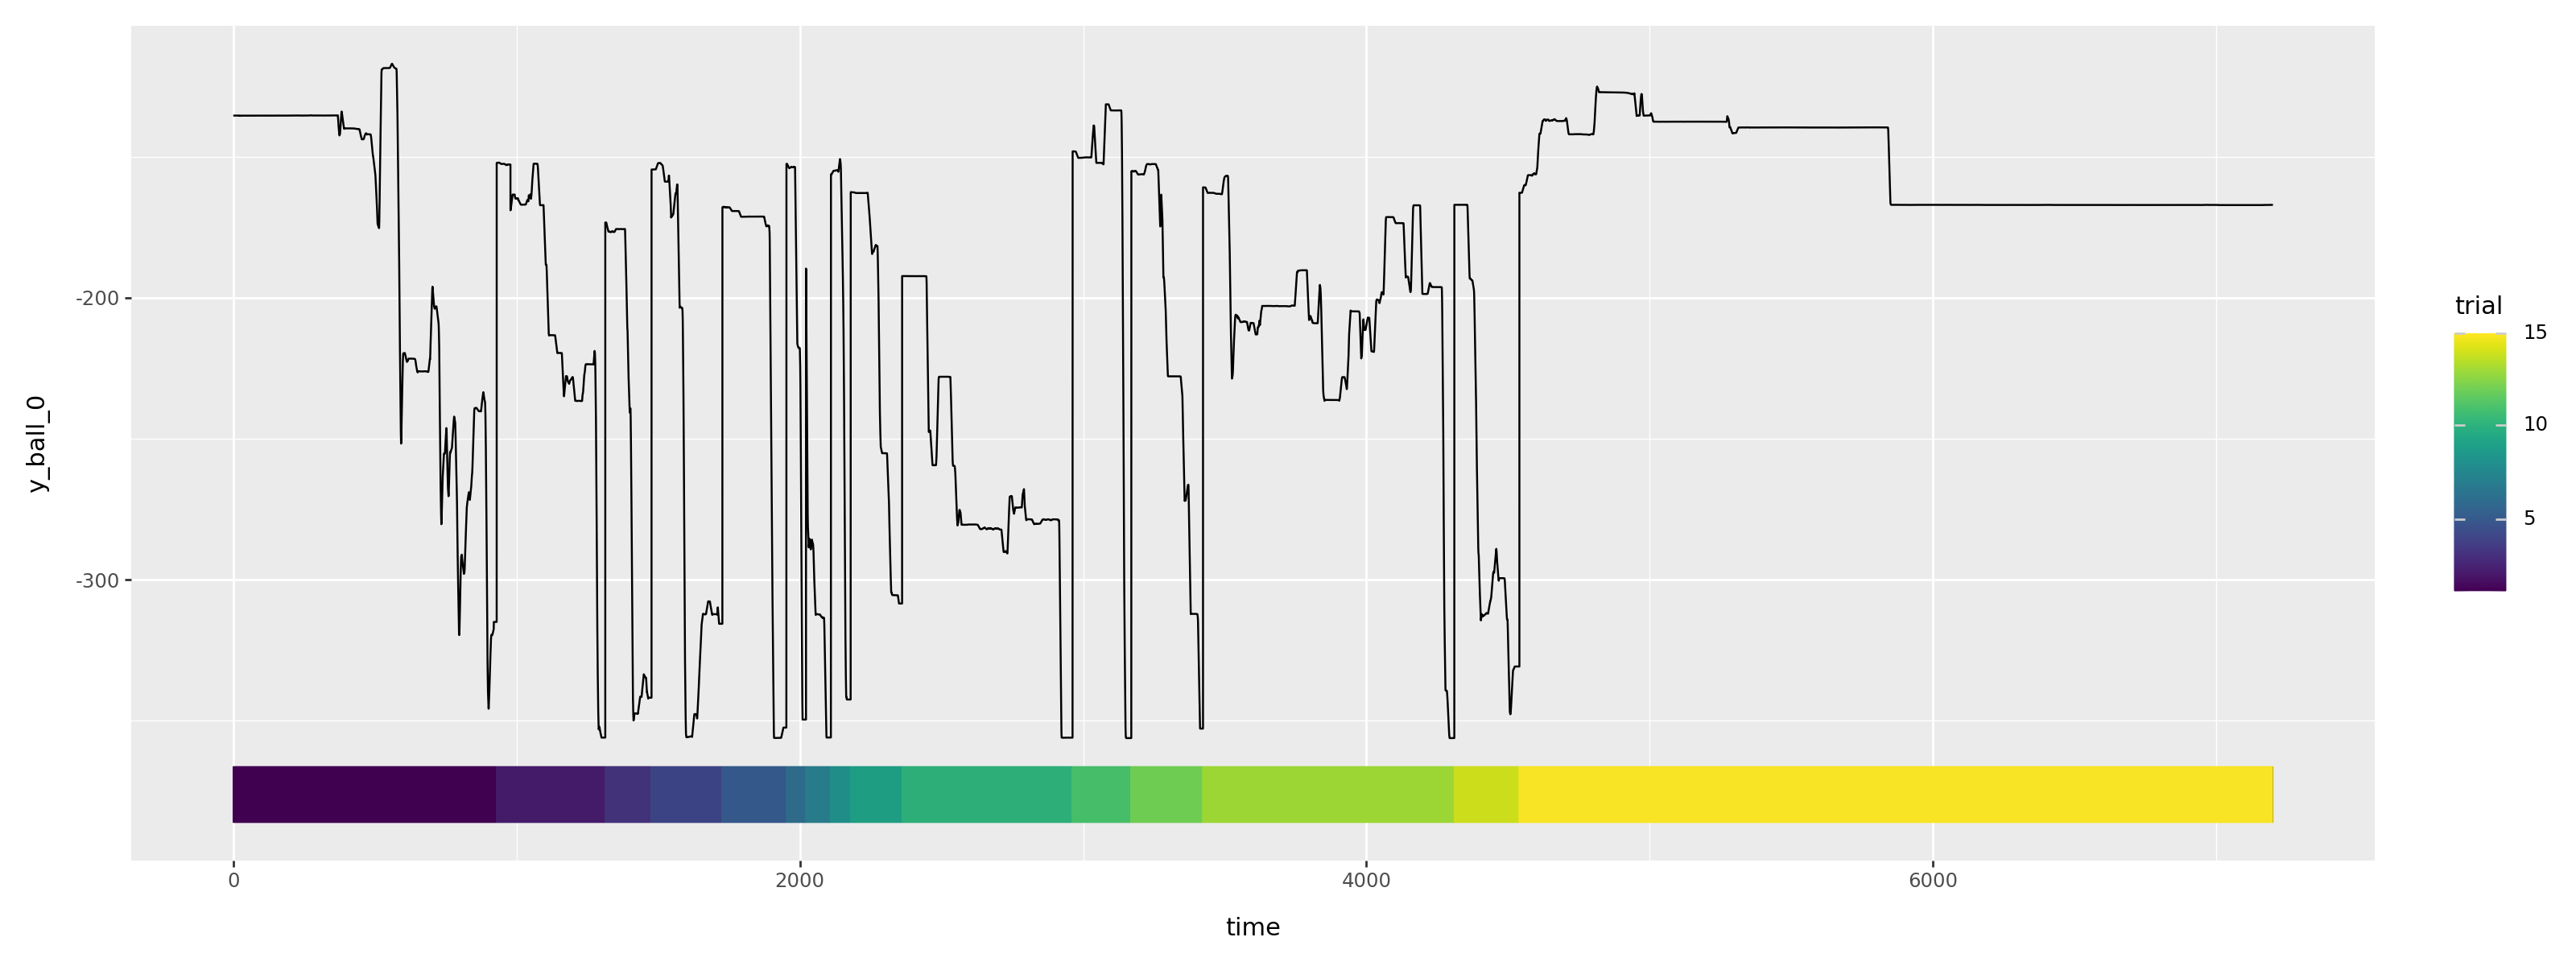

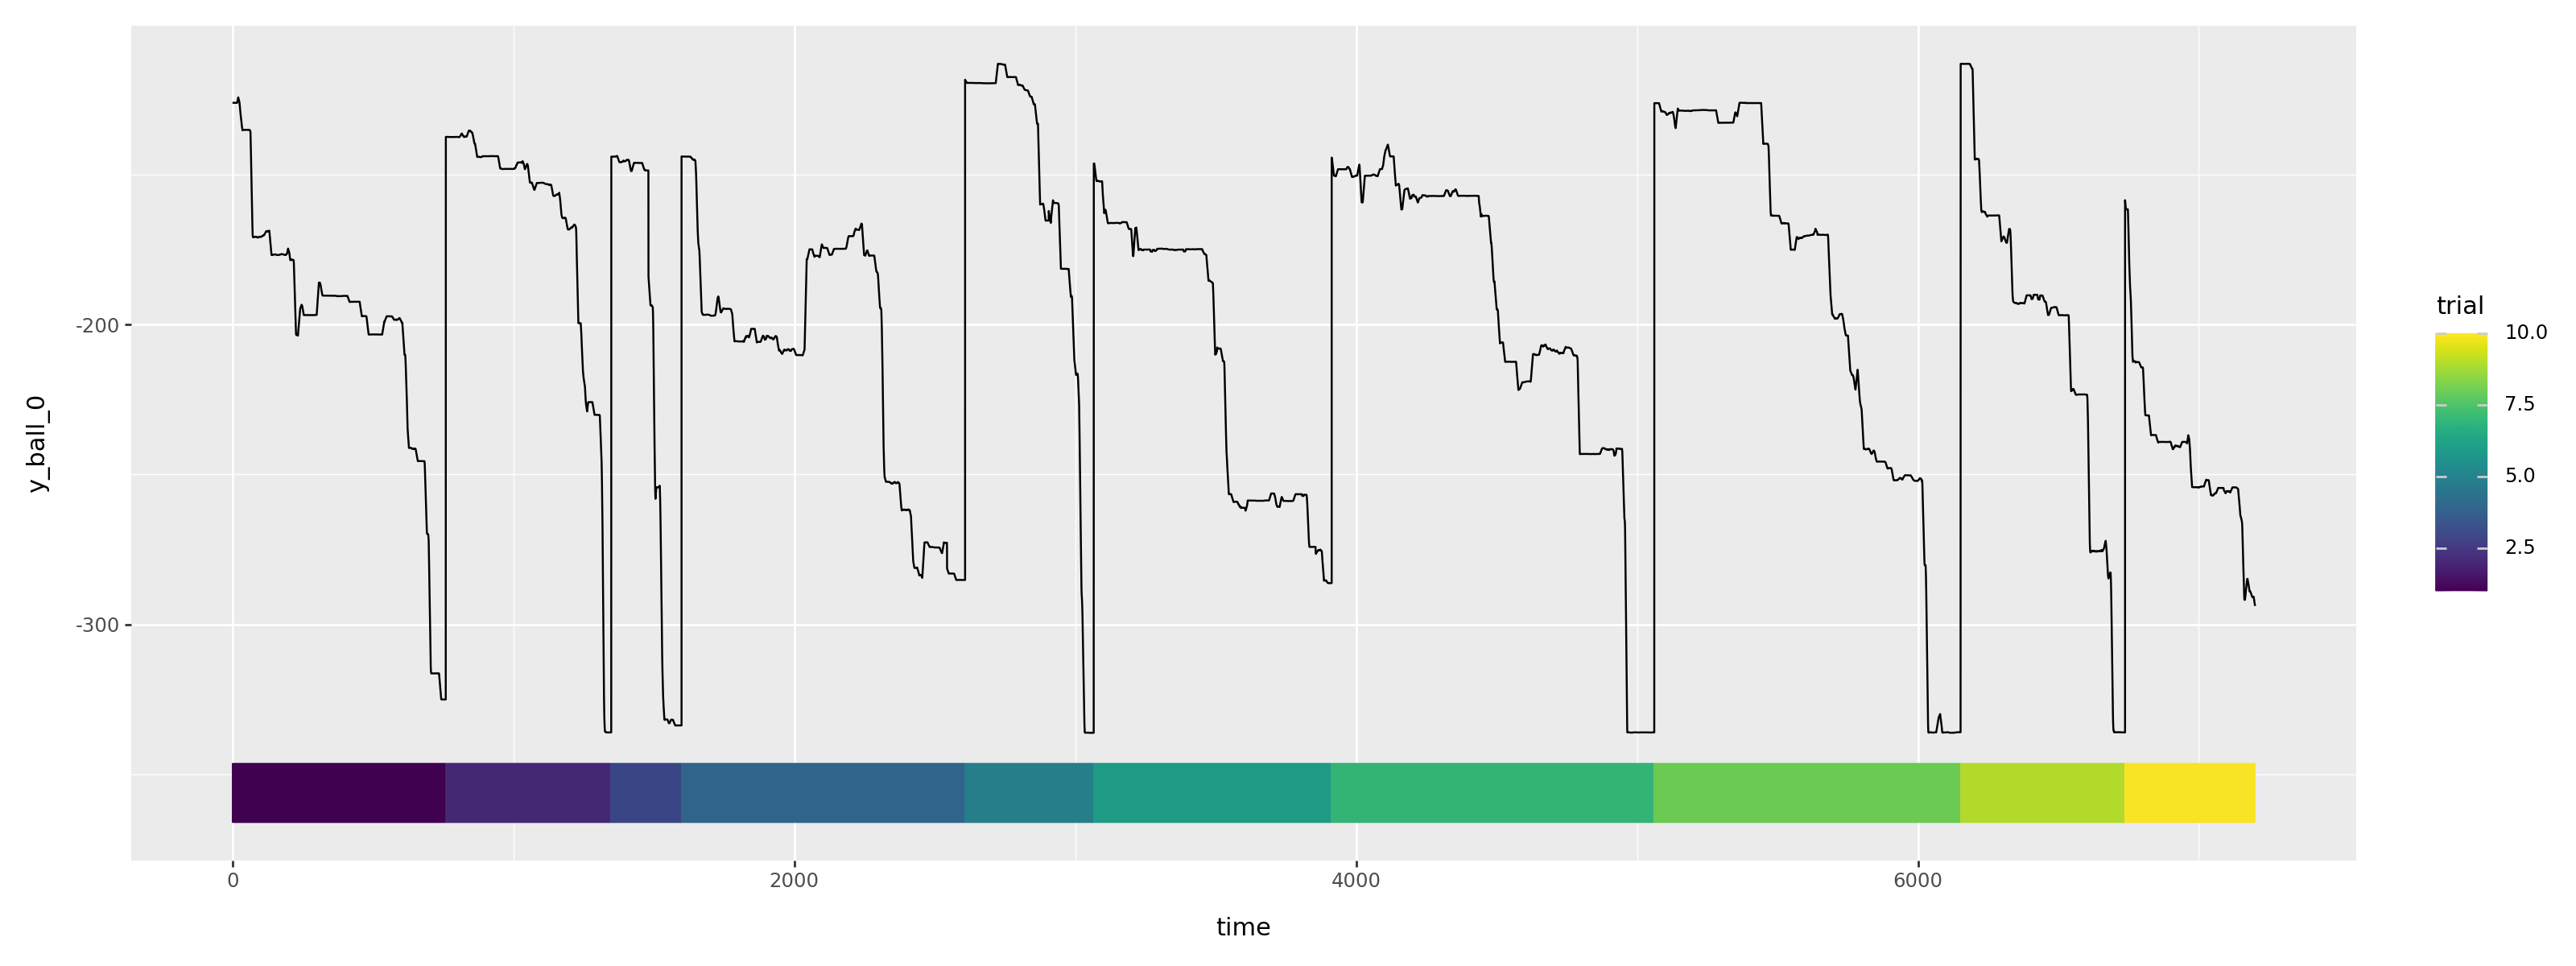

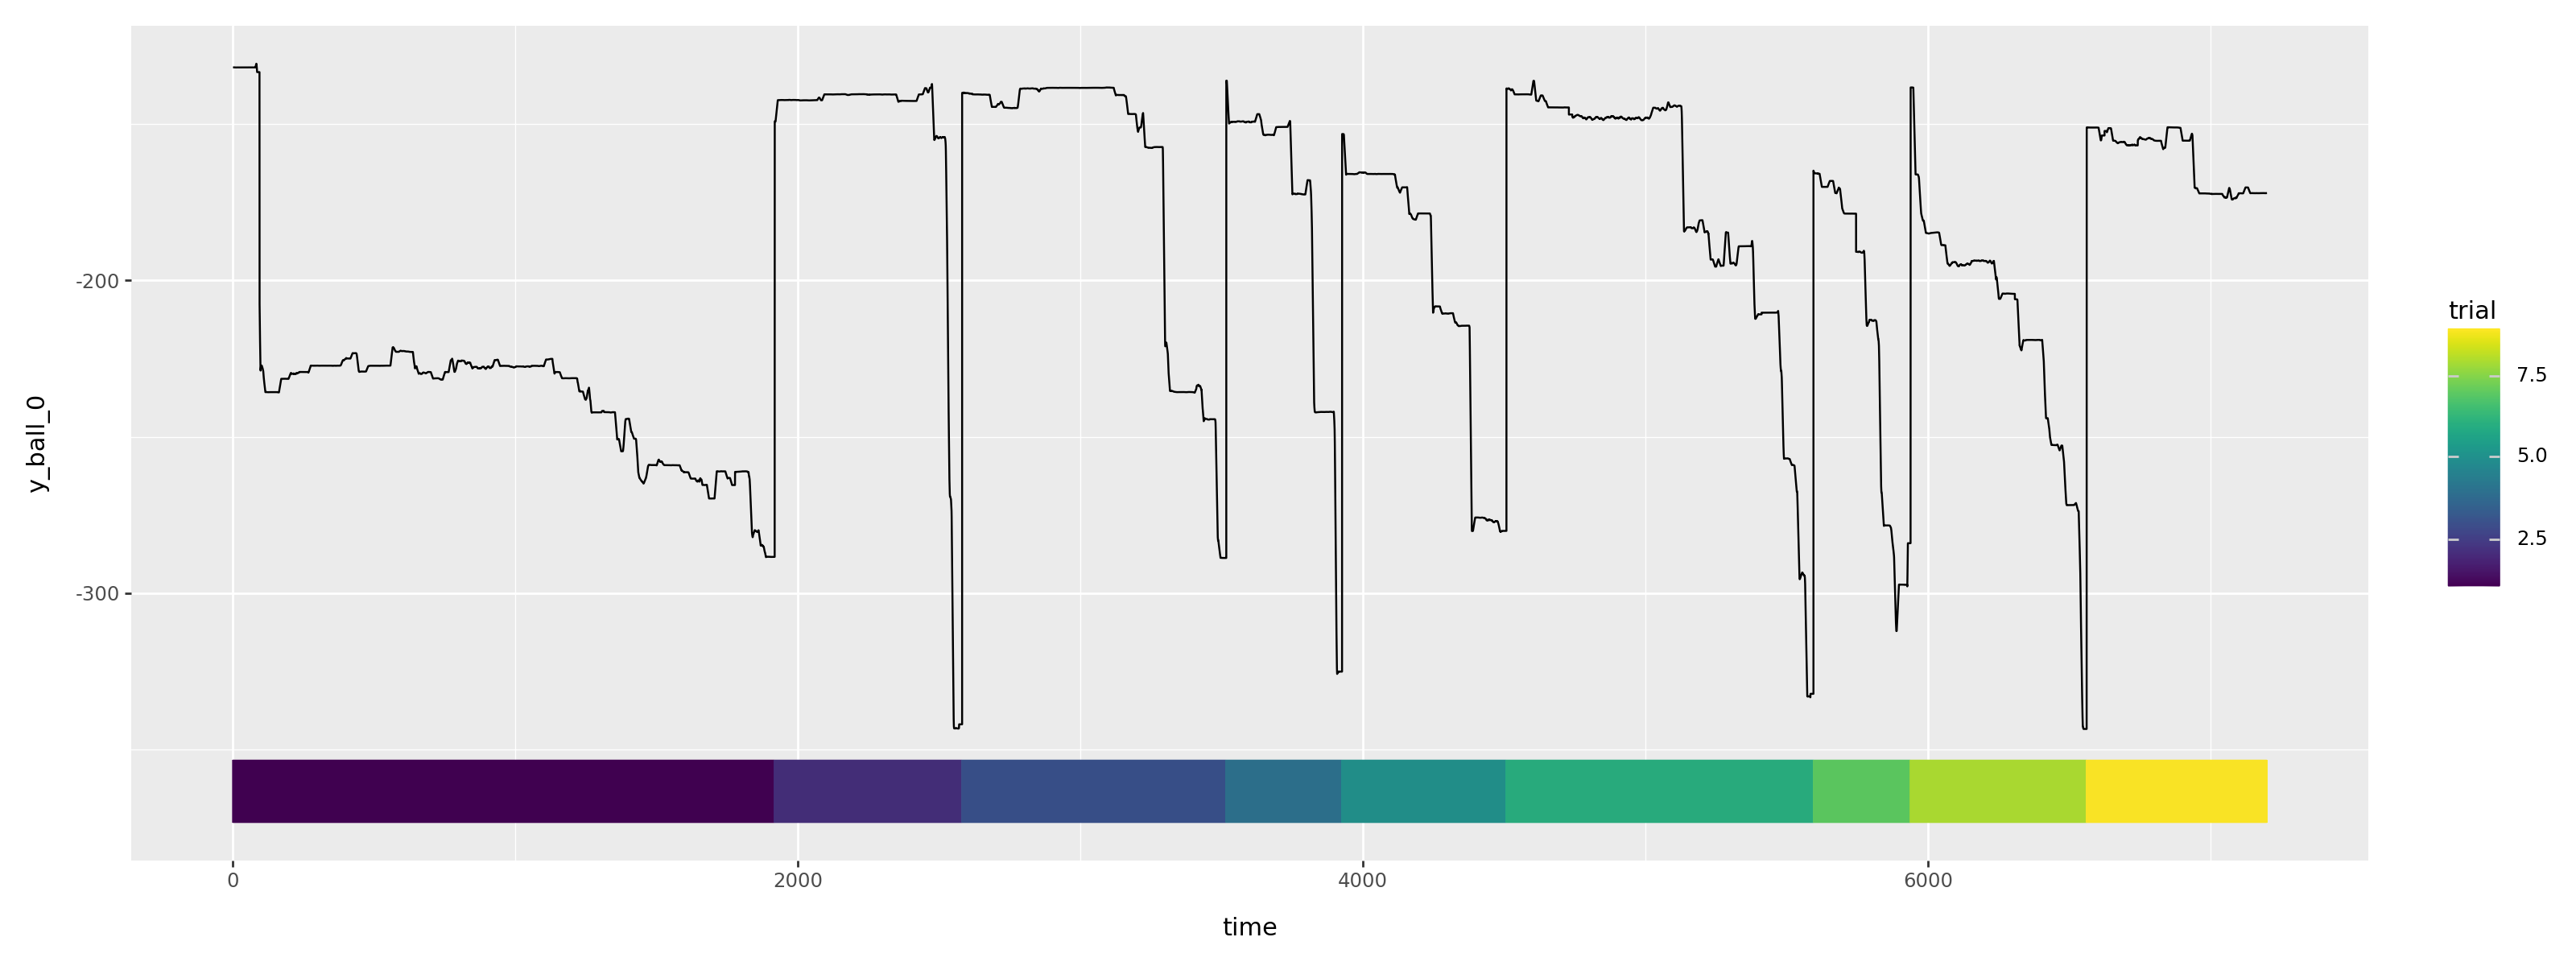

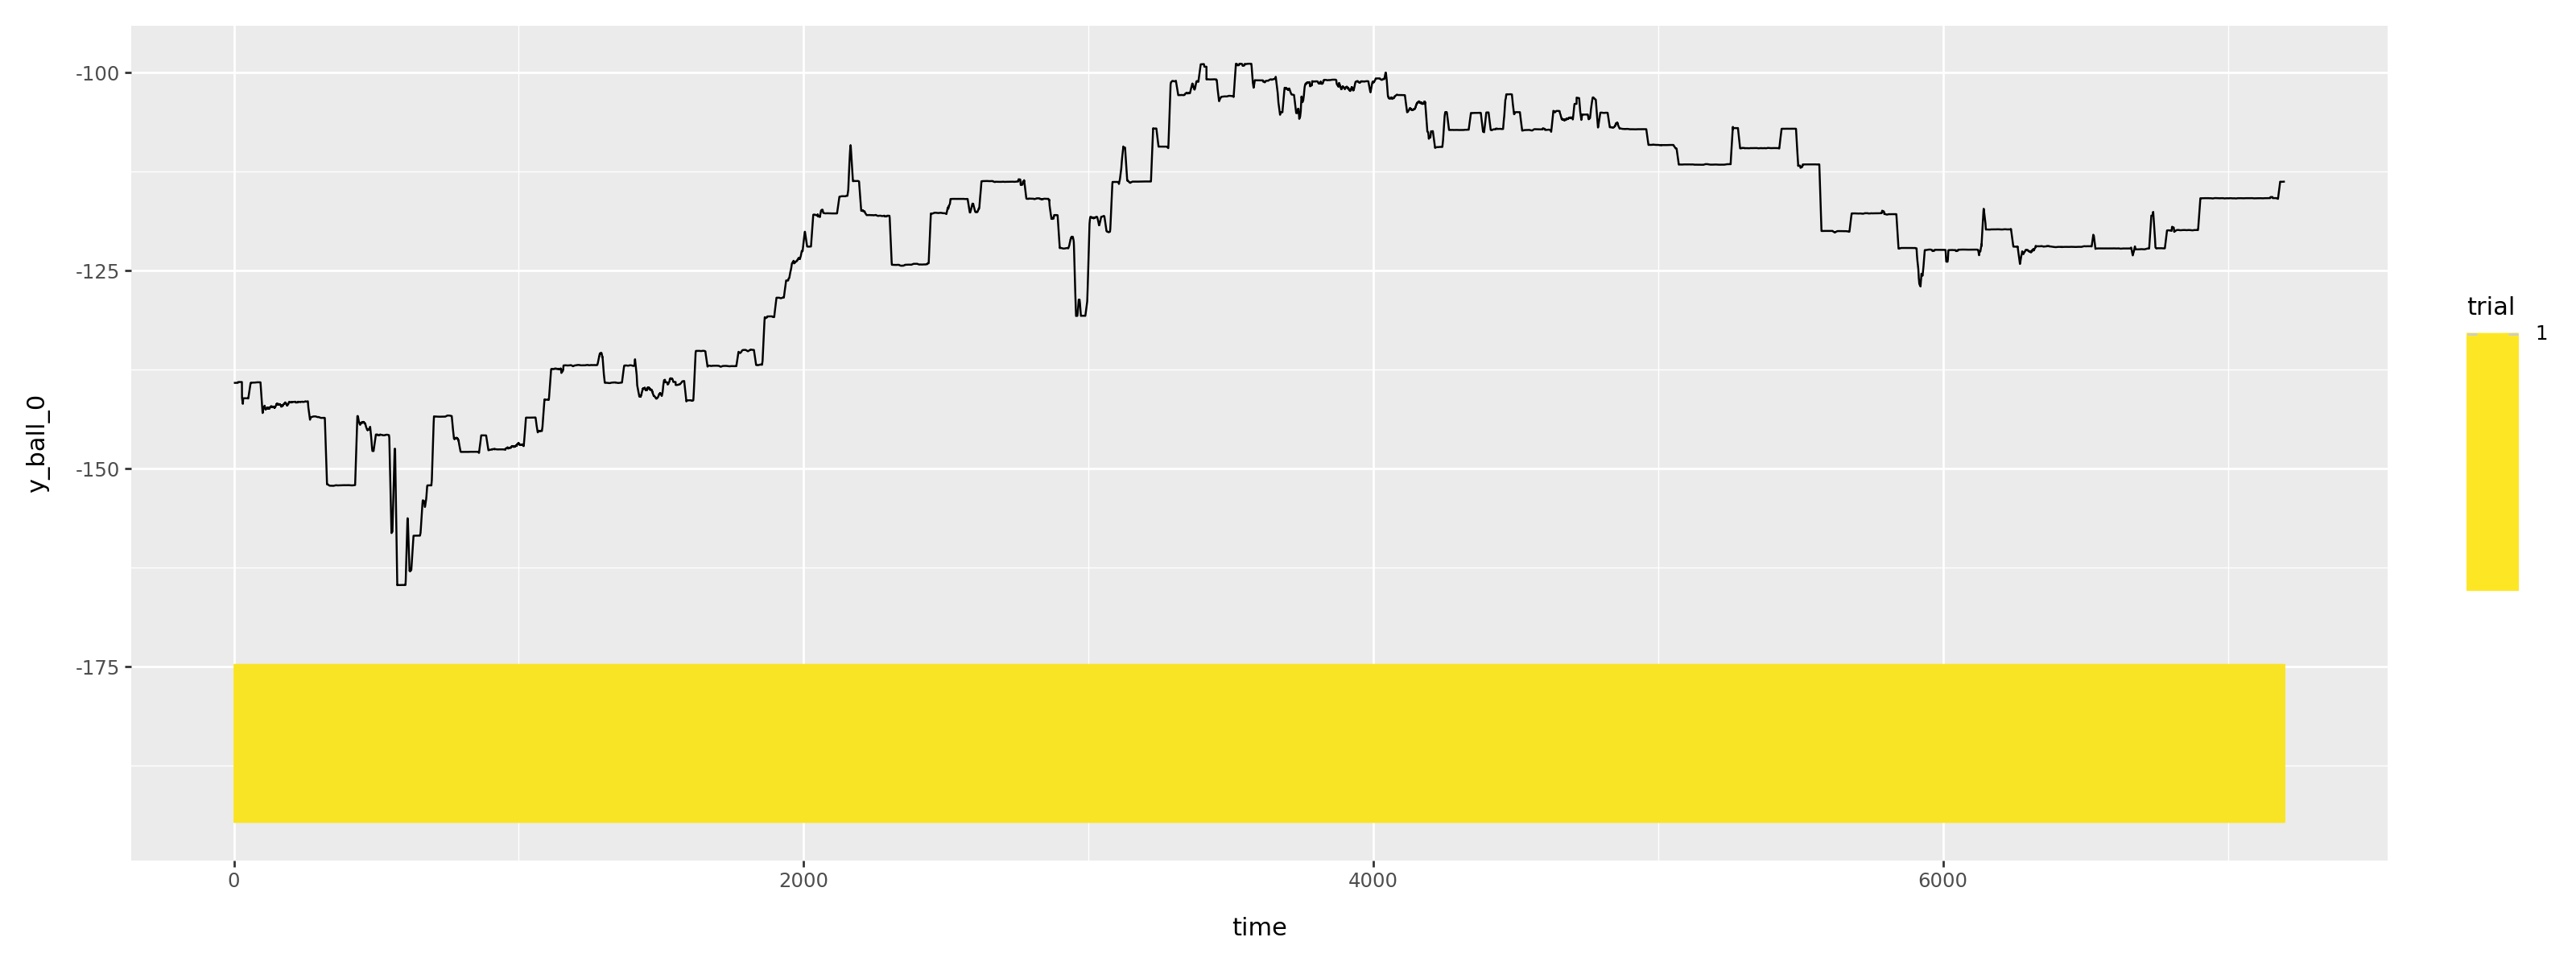

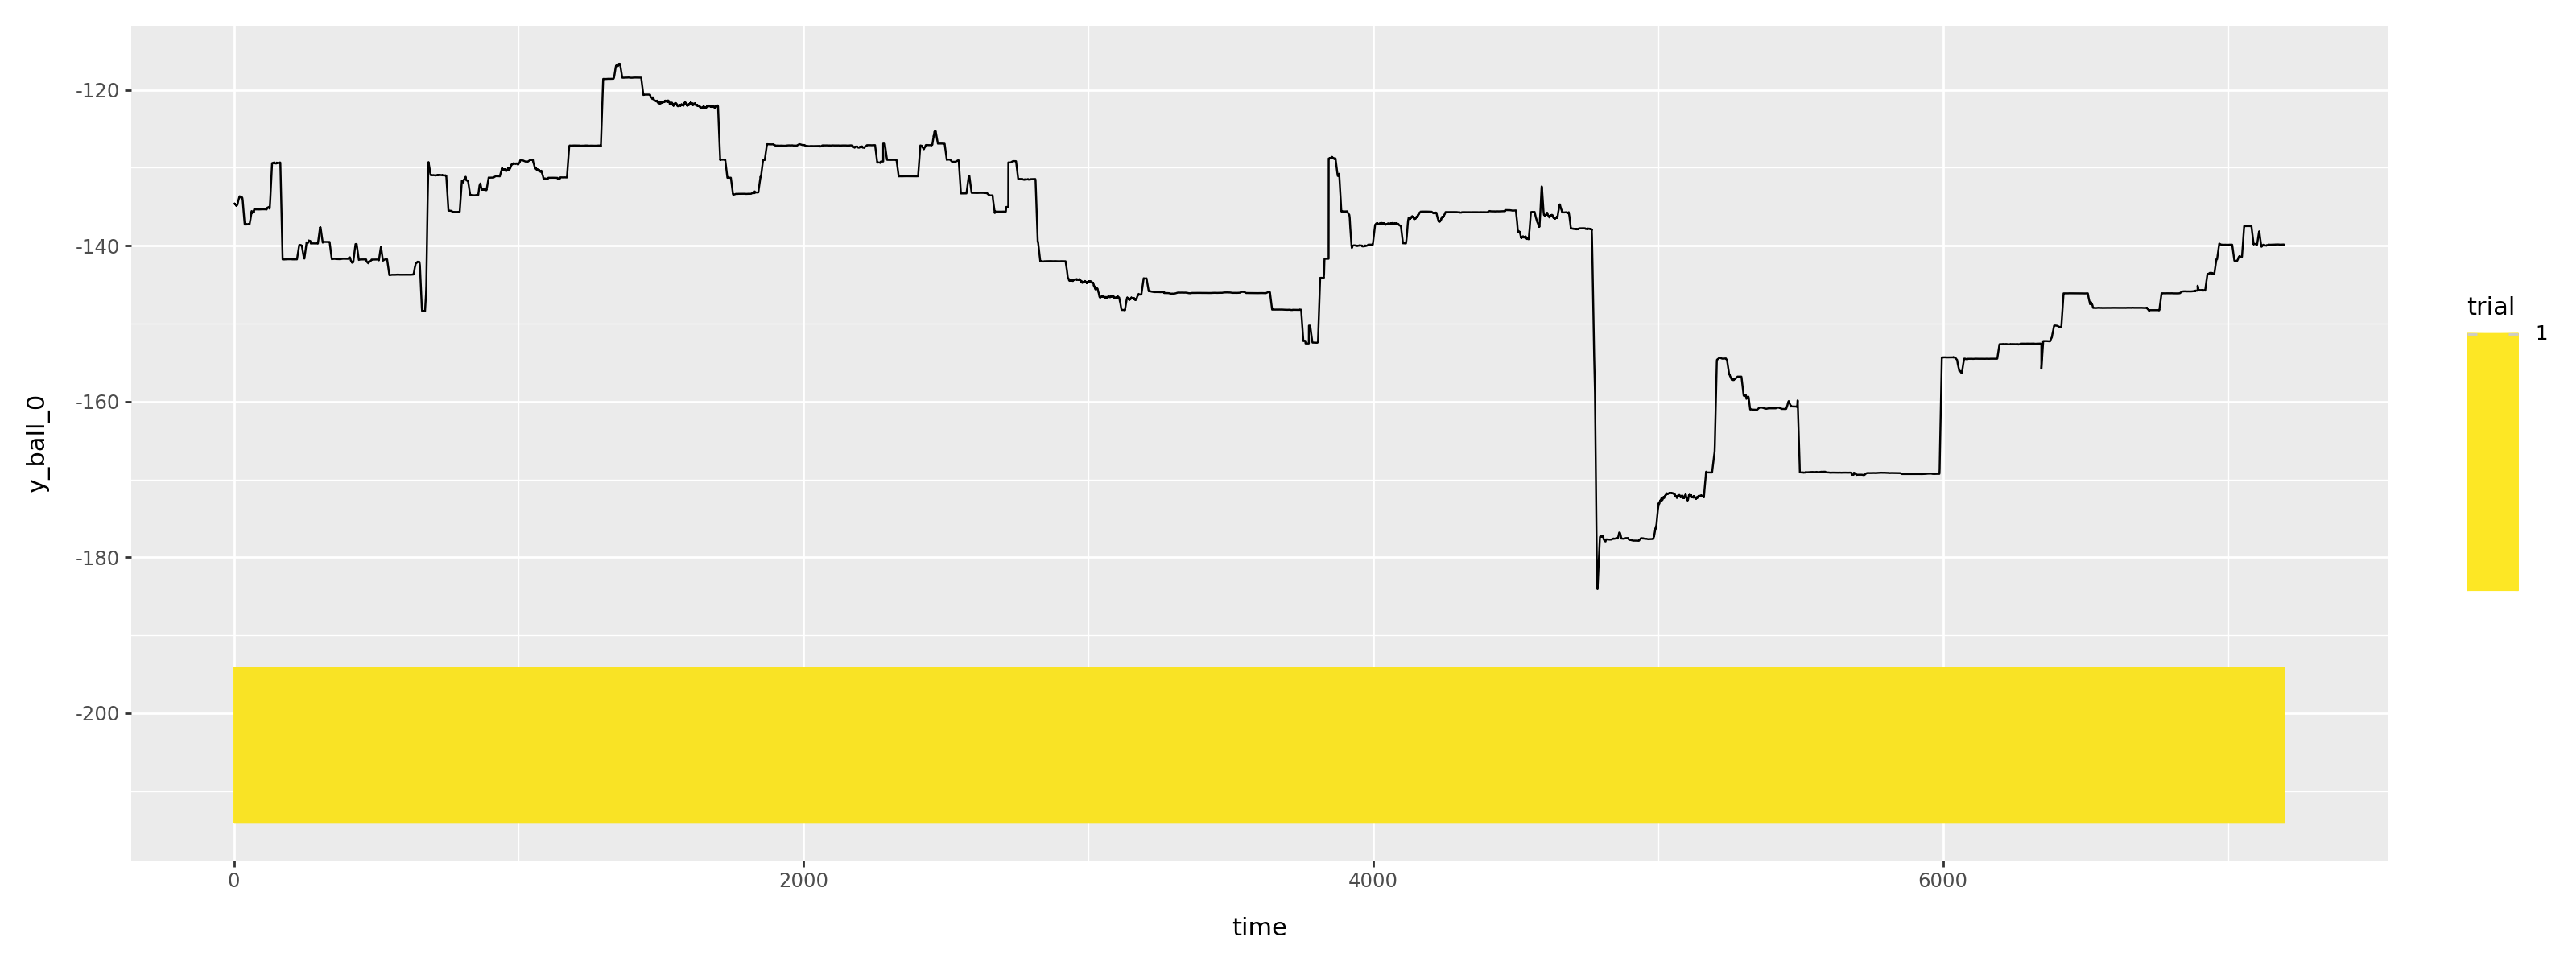

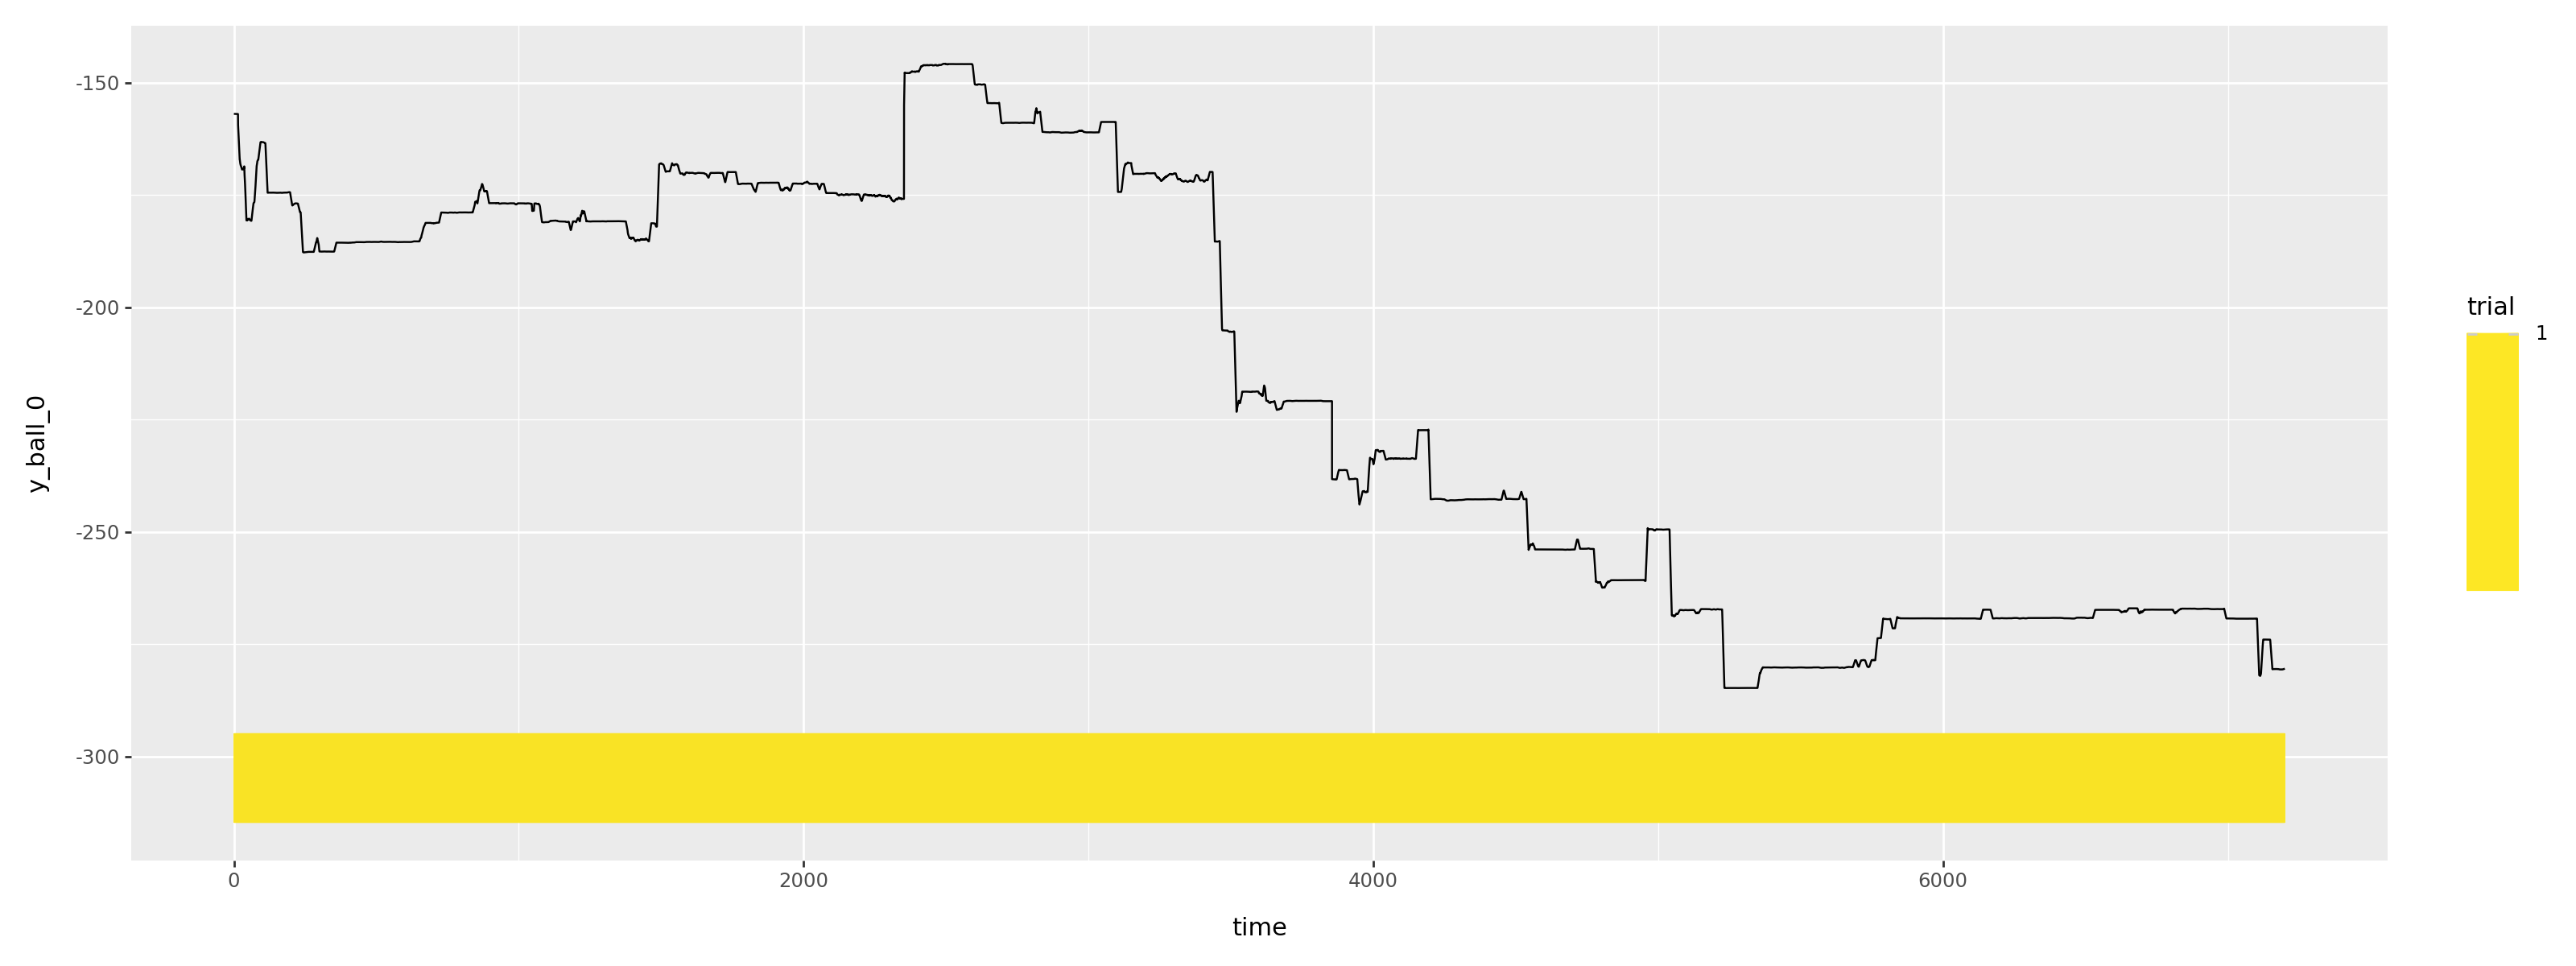

In [115]:
for fly in completed_trials.get_column("fly")[:3]:
    fly_data_with_trials = detect_trials(data.filter(fly=fly).get_column("y_ball_0"))
    plot_fly_trials(fly_data_with_trials).show()

for fly in completed_trials.get_column("fly")[-3:]:
    fly_data_with_trials = detect_trials(data.filter(fly=fly).get_column("y_ball_0"))
    plot_fly_trials(fly_data_with_trials).show()